# <font color='blue'>Projeto 2 - PARTE 1</font>
# <font color='blue'>Predição do Número de Estudantes Desvinculados em Cursos de Graduação no Brasil Utilizando Técnicas de Machine Learning</font>

In [1]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import PowerTransformer
import gc
import warnings
warnings.filterwarnings('ignore')

In [2]:
# !pip install -q -U watermark

In [3]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Mauricio Vinhote"

Author: Mauricio Vinhote



# Execução do Projeto 2 (PARTE 3)

## 1. Preparação do dataframe e seleção de variáveis

Antes de abrirmos do dataframe, estabelecemos o dicionário de dados e a lista de variáveis do dataframe.

In [4]:
dicionario_cursos = {
    'CO_CINE_AREA_DETALHADA': 'Código de identificação da área detalhada, conforme adaptação da Classificação Internacional Normalizada da Educação Cine/Unesco',
    'CO_CINE_AREA_ESPECIFICA': 'Código de identificação da área específica, conforme adaptação da Classificação Internacional Normalizada da Educação Cine/Unesco',
    'CO_CINE_AREA_GERAL': 'Código de identificação da área geral, conforme adaptação da Classificação Internacional Normalizada da Educação Cine/Unesco',
    'CO_IES': 'Código da Instituição',
    'CO_MUNICIPIO': 'Código do IBGE do Município do local de oferta do curso',
    'CO_REGIAO': 'Código da região geográfica do local de oferta do curso',
    'CO_UF': 'Código do IBGE da Unidade da Federação do local de oferta do curso',
    'IN_CAPITAL': 'Informa se o local de oferta do curso está localizado na capital da Unidade da Federação',
    'NO_CINE_AREA_DETALHADA': 'Nome da área detalhada, conforme adaptação da Classificação Internacional Normalizada da Educação Cine/Unesco',
    'NO_CINE_AREA_ESPECIFICA': 'Nome da área específica, conforme adaptação da Classificação Internacional Normalizada da Educação Cine/Unesco',
    'NO_CINE_AREA_GERAL': 'Nome da área geral, conforme adaptação da Classificação Internacional Normalizada da Educação Cine/Unesco',
    'NO_CINE_ROTULO': 'Nome do curso, conforme adaptação da Classificação Internacional Normalizada da Educação Cine/Unesco',
    'NO_MUNICIPIO': 'Nome do Município do local de oferta do curso',
    'NO_REGIAO': 'Nome da região geográfica do local de oferta do curso',
    'NO_UF': 'Nome da Unidade da Federação do local de oferta do curso',
    'NU_ANO_CENSO': 'Ano de referência do Censo da Educação Superior',
    'QT_ALUNO_DEFICIENTE': 'Quantidade de alunos com deficiência, transtorno global do desenvolvimento ou altas habilidades/superdotação',
    'QT_APOIO_SOCIAL': 'Quantidade de alunos que recebem algum tipo de apoio social',
    'QT_ATIV_EXTRACURRICULAR': 'Quantidade de alunos que participam de algum tipo de atividade extracurricular',
    'QT_CONC': 'Quantidade de concluintes',
    'QT_CONC_0_17': 'Quantidade de concluintes - Até 17 anos de idade',
    'QT_CONC_18_24': 'Quantidade de concluintes - De 18 a 24 anos de idade',
    'QT_CONC_25_29': 'Quantidade de concluintes - De 25 a 29 anos de idade',
    'QT_CONC_30_34': 'Quantidade de concluintes - De 30 a 34 anos de idade',
    'QT_CONC_35_39': 'Quantidade de concluintes - De 35 a 39 anos de idade',
    'QT_CONC_40_49': 'Quantidade de concluintes - De 40 a 49 anos de idade',
    'QT_CONC_50_59': 'Quantidade de concluintes - De 50 a 59 anos de idade',
    'QT_CONC_60_MAIS': 'Quantidade de concluintes - De 60 a 59 anos de idade',
    'QT_CONC_AMARELA': 'Quantidade de concluintes - Cor/Raça amarela',
    'QT_CONC_APOIO_SOCIAL': 'Quantidade de concluintes que recebem algum tipo de apoio social',
    'QT_CONC_ATIV_EXTRACURRICULAR': 'Quantidade de concluintes que participam de algum tipo de atividade extracurricular',
    'QT_CONC_BRANCA': 'Quantidade de concluintes - Cor/Raça branca',
    'QT_CONC_CORND': 'Quantidade de concluintes - Cor/Raça não dispõe da informação ou não declarada',
    'QT_CONC_DEFICIENTE': 'Quantidade de concluintes com deficiência, transtorno global do desenvolvimento ou altas habilidades/superdotação',
    'QT_CONC_DIURNO': 'Quantidade de concluintes no turno diurno',
    'QT_CONC_FEM': 'Quantidade de concluintes do sexo feminino',
    'QT_CONC_FIES': 'Quantidade de concluintes que utilizam financiamento estudantil reembolsável - FIES',
    'QT_CONC_FINANC': 'Quantidade de concluintes que utilizam financiamento estudantil',
    'QT_CONC_FINANC_NREEMB': 'Quantidade de concluintes que utilizam financiamento estudantil não reembolsável',
    'QT_CONC_FINANC_NREEMB_OUTROS': 'Quantidade de concluintes que utilizam financiamento estudantil não reembolsável - pelo governo estadual, municipal, entidades externas à IES e outras entidades',
    'QT_CONC_FINANC_REEMB': 'Quantidade de concluintes que utilizam financiamento estudantil reembolsável',
    'QT_CONC_FINANC_REEMB_OUTROS': 'Quantidade de concluintes que utilizam financiamento estudantil reembolsável - pelo governo estadual, municipal, entidades externas à IES e outras entidades',
    'QT_CONC_INDIGENA': 'Quantidade de concluintes - Cor/Raça indígena',
    'QT_CONC_MASC': 'Quantidade de concluintes do sexo masculino',
    'QT_CONC_MOB_ACADEMICA': 'Quantidade de concluintes que se vincularam temporariamente a outra instituição, sendo ela nacional ou internacional',
    'QT_CONC_NACBRAS': 'Quantidade de concluintes - nacionalidade brasileira ou brasileira - nascido no exterior ou naturalizado',
    'QT_CONC_NACESTRANG': 'Quantidade de concluintes - nacionalidade estrangeira',
    'QT_CONC_NOTURNO': 'Quantidade de concluintes no turno noturno',
    'QT_CONC_NRPFIES': 'Quantidade de concluintes que utilizam financiamento estudantil não reembolsável - administrado pela instituição',
    'QT_CONC_PARDA': 'Quantidade de concluintes - Cor/Raça parda',
    'QT_CONC_PARFOR': 'Quantidade de concluintes que participam do programa especial para a formação de professores em exercício na rede pública de educação básica (PARFOR)',
    'QT_CONC_PRETA': 'Quantidade de concluintes - Cor/Raça preta',
    'QT_CONC_PROCESCPRIVADA': 'Quantidade de concluintes que terminaram o ensino médio em escolas privadas',
    'QT_CONC_PROCESCPUBLICA': 'Quantidade de concluintes que terminaram o ensino médio em escolas públicas',
    'QT_CONC_PROCNAOINFORMADA': 'Quantidade de concluintes que não informaram o tipo de escola que terminaram o ensino médio',
    'QT_CONC_PROUNII': 'Quantidade de concluintes que utilizam financiamento estudantil não reembolsável - PROUNI Integral',
    'QT_CONC_PROUNIP': 'Quantidade de concluintes que utilizam financiamento estudantil não reembolsável - PROUNI Parcial',
    'QT_CONC_RESERVA_VAGA': 'Quantidade de concluintes que ingressaram por meio de política de ação afirmativa ou por programa diferenciado de destinação de vagas',
    'QT_CONC_RPFIES': 'Quantidade de concluintes que utilizam financiamento estudantil reembolsável - administrado pela instituição',
    'QT_CONC_RVOUTROS': 'Quantidade de concluintes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - outros tipos',
    'QT_CONC_RVPDEF': 'Quantidade de concluintes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - pessoas com deficiência',
    'QT_CONC_RVREDEPUBLICA': 'Quantidade de concluintes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - escola pública',
    'QT_CONC_RVSOCIAL_RF': 'Quantidade de concluintes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - cunho social/renda familiar',
    'QT_CURSO': 'Quantidade de cursos',
    'QT_ING': 'Quantidade de ingressantes',
    'QT_ING_0_17': 'Quantidade de ingressantes - Até 17 anos de idade',
    'QT_ING_18_24': 'Quantidade de ingressantes - De 18 a 24 anos de idade',
    'QT_ING_25_29': 'Quantidade de ingressantes - De 25 a 29 anos de idade',
    'QT_ING_30_34': 'Quantidade de ingressantes - De 30 a 34 anos de idade',
    'QT_ING_35_39': 'Quantidade de ingressantes - De 35 a 39 anos de idade',
    'QT_ING_40_49': 'Quantidade de ingressantes - De 40 a 49 anos de idade',
    'QT_ING_50_59': 'Quantidade de ingressantes - De 50 a 59 anos de idade',
    'QT_ING_60_MAIS': 'Quantidade de ingressantes - De 60 anos ou mais',
    'QT_ING_AMARELA': 'Quantidade de ingressantes - Cor/Raça amarela',
    'QT_ING_APOIO_SOCIAL': 'Quantidade de ingressantes que recebem algum tipo de apoio social',
    'QT_ING_ATIV_EXTRACURRICULAR': 'Quantidade de ingressantes que participam de algum tipo de atividade extracurricular',
    'QT_ING_AVALIACAO_SERIADA': 'Quantidade de ingressantes por avaliação seriada',
    'QT_ING_BRANCA': 'Quantidade de ingressantes - Cor/Raça branca',
    'QT_ING_CORND': 'Quantidade de ingressantes - Cor/Raça não dispõe da informação ou não declarada',
    'QT_ING_DEFICIENTE': 'Quantidade de ingressantes com deficiência, transtorno global do desenvolvimento ou altas habilidades/superdotação',
    'QT_ING_DIURNO': 'Quantidade de ingressantes no turno diurno',
    'QT_ING_EGR': 'Quantidade de ingressantes por outras formas de ingresso',
    'QT_ING_ENEM': 'Quantidade de ingressantes pelo ENEM',
    'QT_ING_FEM': 'Quantidade de ingressantes do sexo feminino',
    'QT_ING_FIES': 'Quantidade de ingressantes que utilizam financiamento estudantil reembolsável - FIES',
    'QT_ING_FINANC': 'Quantidade de ingressantes que utilizam financiamento estudantil',
    'QT_ING_FINANC_NREEMB': 'Quantidade de ingressantes que utilizam financiamento estudantil não reembolsável',
    'QT_ING_FINANC_NREEMB_OUTROS': 'Quantidade de ingressantes que utilizam financiamento estudantil não reembolsável - pelo governo estadual, municipal, entidades externas à IES e outras entidades',
    'QT_ING_FINANC_REEMB': 'Quantidade de ingressantes que utilizam financiamento estudantil reembolsável',
    'QT_ING_FINANC_REEMB_OUTROS': 'Quantidade de ingressantes que utilizam financiamento estudantil reembolsável - pelo governo estadual, municipal, entidades externas à IES e outras entidades',
    'QT_ING_INDIGENA': 'Quantidade de ingressantes - Cor/Raça indígena',
    'QT_ING_MASC': 'Quantidade de ingressantes do sexo masculino',
    'QT_ING_MOB_ACADEMICA': 'Quantidade de ingressantes que se vincularam temporariamente a outra instituição, sendo ela nacional ou internacional',
    'QT_ING_NACBRAS': 'Quantidade de ingressantes - nacionalidade brasileira ou brasileira - nascido no exterior ou naturalizado',
    'QT_ING_NACESTRANG': 'Quantidade de ingressantes - nacionalidade estrangeira',
    'QT_ING_NOTURNO': 'Quantidade de ingressantes no turno noturno',
    'QT_ING_NRPFIES': 'Quantidade de ingressantes que utilizam financiamento estudantil não reembolsável - administrado pela instituição',
    'QT_ING_OUTRA_FORMA': 'Quantidade de ingressantes por outras formas de ingresso',
    'QT_ING_OUTRO_TIPO_SELECAO': 'Quantidade de ingressantes em outro tipo de seleção',
    'QT_ING_PARDA': 'Quantidade de ingressantes - Cor/Raça parda',
    'QT_ING_PARFOR': 'Quantidade de ingressantes que participam do programa especial para a formação de professores em exercício na rede pública de educação básica (PARFOR)',
    'QT_ING_PRETA': 'Quantidade de ingressantes - Cor/Raça preta',
    'QT_ING_PROCESCPRIVADA': 'Quantidade de ingressantes que terminaram o ensino médio em escolas privadas',
    'QT_ING_PROCESCPUBLICA': 'Quantidade de ingressantes que terminaram o ensino médio em escolas públicas',
    'QT_ING_PROCNAOINFORMADA': 'Quantidade de ingressantes que não informaram o tipo de escola que terminaram o ensino médio',
    'QT_ING_PROC_SELETIVO': 'Quantidade de ingressantes nos processos seletivos',
    'QT_ING_PROUNII': 'Quantidade de ingressantes que utilizam financiamento estudantil não reembolsável - PROUNI Integral',
    'QT_ING_PROUNIP': 'Quantidade de ingressantes que utilizam financiamento estudantil não reembolsável - PROUNI Parcial',
    'QT_ING_RESERVA_VAGA': 'Quantidade de ingressantes que ingressaram por meio de política de ação afirmativa ou por programa diferenciado de destinação de vagas',
    'QT_ING_RPFIES': 'Quantidade de ingressantes que utilizam financiamento estudantil reembolsável - administrado pela instituição',
    'QT_ING_RVETNICO': 'Quantidade de ingressantes que participam do programa de reserva de vagas - cunho étnico',
    'QT_ING_RVOUTROS': 'Quantidade de ingressantes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - outros tipos',
    'QT_ING_RVPDEF': 'Quantidade de ingressantes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - pessoas com deficiência',
    'QT_ING_RVREDEPUBLICA': 'Quantidade de ingressantes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - escola pública',
    'QT_ING_RVSOCIAL_RF': 'Quantidade de ingressantes que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - cunho social/renda familiar',
    'QT_ING_SELECAO_SIMPLIFICA': 'Quantidade de ingressantes por meio de seleção simplificada',
    'QT_ING_VESTIBULAR': 'Quantidade de ingressantes por vestibular',
    'QT_ING_VG_NOVA': 'Quantidade de ingressantes em vagas novas',
    'QT_ING_VG_PROG_ESPECIAL': 'Quantidade de ingressantes por meio de vagas para programas especiais',
    'QT_ING_VG_REMANESC': 'Quantidade de ingressantes por meio de vagas remanescentes',
    'QT_INSCRITO_TOTAL': 'Quantidade total de inscritos',
    'QT_INSCRITO_TOTAL_DIURNO': 'Quantidade total de inscritos no turno diurno',
    'QT_INSCRITO_TOTAL_EAD': 'Quantidade total de inscritos no curso a distância',
    'QT_INSCRITO_TOTAL_NOTURNO': 'Quantidade total de inscritos no turno noturno',
    'QT_INSC_PROC_SELETIVO': 'Quantidade de inscritos nos processos seletivos',
    'QT_INSC_VG_NOVA': 'Quantidade de inscritos no processo seletivo de vagas novas',
    'QT_INSC_VG_PROG_ESPECIAL': 'Quantidade de inscritos no processo seletivo de vagas oferecidas para programas especiais',
    'QT_INSC_VG_REMANESC': 'Quantidade de inscritos no processo seletivo de vagas remanescentes',
    'QT_MAT': 'Quantidade de matrículas',
    'QT_MAT_0_17': 'Quantidade de matrículas - Até 17 anos de idade',
    'QT_MAT_18_24': 'Quantidade de matrículas - De 18 a 24 anos de idade',
    'QT_MAT_25_29': 'Quantidade de matrículas - De 25 a 29 anos de idade',
    'QT_MAT_30_34': 'Quantidade de matrículas - De 30 a 34 anos de idade',
    'QT_MAT_35_39': 'Quantidade de matrículas - De 35 a 39 anos de idade',
    'QT_MAT_40_49': 'Quantidade de matrículas - De 40 a 49 anos de idade',
    'QT_MAT_50_59': 'Quantidade de matrículas - De 50 a 59 anos de idade',
    'QT_MAT_60_MAIS': 'Quantidade de matrículas - De 60 ou mais anos de idade',
    'QT_MAT_AMARELA': 'Quantidade de matrículas - Cor/Raça amarela',
    'QT_MAT_APOIO_SOCIAL': 'Quantidade de matrículas de alunos que recebem algum tipo de apoio social',
    'QT_MAT_ATIV_EXTRACURRICULAR': 'Quantidade de matrículas de alunos que participam de algum tipo de atividade extracurricular',
    'QT_MAT_BRANCA': 'Quantidade de matrículas - Cor/Raça branca',
    'QT_MAT_CORND': 'Quantidade de matrículas - Cor/Raça não dispõe da informação ou não declarada',
    'QT_MAT_DEFICIENTE': 'Quantidade de matrículas - alunos com deficiência, transtorno global do desenvolvimento ou altas habilidades/superdotação',
    'QT_MAT_DIURNO': 'Quantidade de matrículas - turno diurno',
    'QT_MAT_FEM': 'Quantidade de matrículas do sexo feminino',
    'QT_MAT_FIES': 'Quantidade de matrículas que utilizam financiamento estudantil reembolsável - FIES',
    'QT_MAT_FINANC': 'Quantidade de matrículas que utilizam financiamento estudantil',
    'QT_MAT_FINANC_NREEMB': 'Quantidade de matrículas que utilizam financiamento estudantil não reembolsável',
    'QT_MAT_FINANC_NREEMB_OUTROS': 'Quantidade de matrículas que utilizam financiamento estudantil não reembolsável - pelo governo estadual, municipal, entidades externas à IES e outras entidades',
    'QT_MAT_FINANC_REEMB': 'Quantidade de matrículas que utilizam financiamento estudantil reembolsável',
    'QT_MAT_FINANC_REEMB_OUTROS': 'Quantidade de matrículas que utilizam financiamento estudantil reembolsável - pelo governo estadual, municipal, entidades externas à IES e outras entidades',
    'QT_MAT_INDIGENA': 'Quantidade de matrículas - Cor/Raça indígena',
    'QT_MAT_MASC': 'Quantidade de matrículas do sexo masculino',
    'QT_MAT_MOB_ACADEMICA': 'Quantidade de alunos regularmente matriculados que se vincularam temporariamente a outra instituição, sendo ela nacional ou internacional',
    'QT_MAT_NACBRAS': 'Quantidade de matrículas - nacionalidade brasileira ou brasileira - nascido no exterior ou naturalizado',
    'QT_MAT_NACESTRANG': 'Quantidade de matrículas - nacionalidade estrangeira',
    'QT_MAT_NOTURNO': 'Quantidade de matrículas - turno noturno',
    'QT_MAT_NRPFIES': 'Quantidade de matrículas que utilizam financiamento estudantil não reembolsável - administrado pela instituição',
    'QT_MAT_PARDA': 'Quantidade de matrículas - Cor/Raça parda',
    'QT_MAT_PARFOR': 'Quantidade de matrículas de alunos que participam do programa especial para a formação de professores em exercício na rede pública de educação básica (PARFOR)',
    'QT_MAT_PRETA': 'Quantidade de matrículas - Cor/Raça preta',
    'QT_MAT_PROCESCPRIVADA': 'Quantidade de matrículas de alunos que terminaram o ensino médio em escolas privadas',
    'QT_MAT_PROCESCPUBLICA': 'Quantidade de matrículas de alunos que terminaram o ensino médio em escolas públicas',
    'QT_MAT_PROCNAOINFORMADA': 'Quantidade de matrículas de alunos que não informaram o tipo de escola que terminaram o ensino médio',
    'QT_MAT_PROUNII': 'Quantidade de matrículas que utilizam financiamento estudantil não reembolsável - PROUNI Integral',
    'QT_MAT_PROUNIP': 'Quantidade de matrículas que utilizam financiamento estudantil não reembolsável - PROUNI Parcial',
    'QT_MAT_RESERVA_VAGA': 'Quantidade de matrículas que ingressaram por meio de política de ação afirmativa ou por programa diferenciado de destinação de vagas',
    'QT_MAT_RPFIES': 'Quantidade de matrículas que utilizam financiamento estudantil reembolsável - administrado pela instituição',
    'QT_MAT_RVETNICO': 'Quantidade de matrículas que participam do programa de reserva de vagas - cunho étnico',
    'QT_MAT_RVOUTROS': 'Quantidade de matrículas que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - outros tipos',
    'QT_MAT_RVPDEF': 'Quantidade de matrículas que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - pessoas com deficiência',
    'QT_MAT_RVREDEPUBLICA': 'Quantidade de matrículas que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - escola pública',
    'QT_MAT_RVSOCIAL_RF': 'Quantidade de matrículas que participam do programa de reserva de vagas ou programa diferenciado de destinação de vagas - cunho social/renda familiar',

    'QT_MOB_ACADEMICA': 'Quantidade de alunos que se vincularam temporariamente a outra instituição, sendo ela nacional ou internacional',
    'QT_PARFOR': 'Quantidade de alunos que participam do programa especial para a formação de professores em exercício na rede pública de educação básica (PARFOR)',
    'QT_SIT_DESVINCULADO': 'Quantidade de alunos com situação de vínculo no curso - aluno desvinculado do curso',
    'QT_SIT_FALECIDO': 'Quantidade de alunos com situação de vínculo no curso - aluno falecido',
    'QT_SIT_TRANCADA': 'Quantidade de alunos com situação de vínculo no curso - matrícula trancada',
    'QT_SIT_TRANSFERIDO': 'Quantidade de alunos com situação de vínculo no curso - aluno transferido para outro curso da mesma IES',

    'QT_VG_NOVA': 'Quantidade de vagas novas oferecidas',
    'QT_VG_PROC_SELETIVO': 'Quantidade de vagas nos processos seletivos',
    'QT_VG_PROG_ESPECIAL': 'Quantidade de vagas oferecidas para programas especiais',
    'QT_VG_REMANESC': 'Quantidade de vagas remanescentes',
    'QT_VG_TOTAL': 'Quantidade total de vagas oferecidas',
    'QT_VG_TOTAL_DIURNO': 'Quantidade total de vagas oferecidas no turno diurno',
    'QT_VG_TOTAL_EAD': 'Quantidade total de vagas oferecidas no curso a distância',
    'QT_VG_TOTAL_NOTURNO': 'Quantidade total de vagas oferecidas no turno noturno',

    'SG_UF': 'Sigla da Unidade da Federação do local de oferta do curso',
    'TP_CATEGORIA_ADMINISTRATIVA': 'Tipo de Categoria Administrativa da IES',
    'TP_GRAU_ACADEMICO': 'Tipo do grau acadêmico conferido ao aluno pela conclusão dos requisitos exigidos pelo curso',
    'TP_MODALIDADE_ENSINO': 'Tipo de modalidade de ensino do curso',
    'TP_NIVEL_ACADEMICO': 'Tipo de nível acadêmico do curso',
    'TP_ORGANIZACAO_ACADEMICA': 'Tipo de Organização Acadêmica da IES',
    'TP_REDE': 'Rede de Ensino'
}


In [5]:
variaveis_cursos = [
    'CO_CINE_AREA_DETALHADA',
    'CO_CINE_AREA_ESPECIFICA',
    'CO_CINE_AREA_GERAL',
    'CO_IES',
    'CO_MUNICIPIO',
    'CO_REGIAO',
    'CO_UF',
    'IN_CAPITAL',
    'NO_CINE_AREA_DETALHADA',
    'NO_CINE_AREA_ESPECIFICA',
    'NO_CINE_AREA_GERAL',
    'NO_CINE_ROTULO',
    'NO_MUNICIPIO',
    'NO_REGIAO',
    'NO_UF',
    'NU_ANO_CENSO',
    'QT_ALUNO_DEFICIENTE',
    'QT_APOIO_SOCIAL',
    'QT_ATIV_EXTRACURRICULAR',
    'QT_CONC',
    'QT_CONC_0_17',
    'QT_CONC_18_24',
    'QT_CONC_25_29',
    'QT_CONC_30_34',
    'QT_CONC_35_39',
    'QT_CONC_40_49',
    'QT_CONC_50_59',
    'QT_CONC_60_MAIS',
    'QT_CONC_AMARELA',
    'QT_CONC_APOIO_SOCIAL',
    'QT_CONC_ATIV_EXTRACURRICULAR',
    'QT_CONC_BRANCA',
    'QT_CONC_CORND',
    'QT_CONC_DEFICIENTE',
    'QT_CONC_DIURNO',
    'QT_CONC_FEM',
    'QT_CONC_FIES',
    'QT_CONC_FINANC',
    'QT_CONC_FINANC_NREEMB',
    'QT_CONC_FINANC_NREEMB_OUTROS',
    'QT_CONC_FINANC_REEMB',
    'QT_CONC_FINANC_REEMB_OUTROS',
    'QT_CONC_INDIGENA',
    'QT_CONC_MASC',
    'QT_CONC_MOB_ACADEMICA',
    'QT_CONC_NACBRAS',
    'QT_CONC_NACESTRANG',
    'QT_CONC_NOTURNO',
    'QT_CONC_NRPFIES',
    'QT_CONC_PARDA',
    'QT_CONC_PARFOR',
    'QT_CONC_PRETA',
    'QT_CONC_PROCESCPRIVADA',
    'QT_CONC_PROCESCPUBLICA',
    'QT_CONC_PROCNAOINFORMADA',
    'QT_CONC_PROUNII',
    'QT_CONC_PROUNIP',
    'QT_CONC_RESERVA_VAGA',
    'QT_CONC_RPFIES',
    'QT_CONC_RVOUTROS',
    'QT_CONC_RVPDEF',
    'QT_CONC_RVREDEPUBLICA',
    'QT_CONC_RVSOCIAL_RF',
    'QT_CURSO',
    'QT_ING',
    'QT_ING_0_17',
    'QT_ING_18_24',
    'QT_ING_25_29',
    'QT_ING_30_34',
    'QT_ING_35_39',
    'QT_ING_40_49',
    'QT_ING_50_59',
    'QT_ING_60_MAIS',
    'QT_ING_AMARELA',
    'QT_ING_APOIO_SOCIAL',
    'QT_ING_ATIV_EXTRACURRICULAR',
    'QT_ING_AVALIACAO_SERIADA',
    'QT_ING_BRANCA',
    'QT_ING_CORND',
    'QT_ING_DEFICIENTE',
    'QT_ING_DIURNO',
    'QT_ING_EGR',
    'QT_ING_ENEM',
    'QT_ING_FEM',
    'QT_ING_FIES',
    'QT_ING_FINANC',
    'QT_ING_FINANC_NREEMB',
    'QT_ING_FINANC_NREEMB_OUTROS',
    'QT_ING_FINANC_REEMB',
    'QT_ING_FINANC_REEMB_OUTROS',
    'QT_ING_INDIGENA',
    'QT_ING_MASC',
    'QT_ING_MOB_ACADEMICA',
    'QT_ING_NACBRAS',
    'QT_ING_NACESTRANG',
    'QT_ING_NOTURNO',
    'QT_ING_NRPFIES',
    'QT_ING_OUTRA_FORMA',
    'QT_ING_OUTRO_TIPO_SELECAO',
    'QT_ING_PARDA',
    'QT_ING_PARFOR',
    'QT_ING_PRETA',
    'QT_ING_PROCESCPRIVADA',
    'QT_ING_PROCESCPUBLICA',
    'QT_ING_PROCNAOINFORMADA',
    'QT_ING_PROC_SELETIVO',
    'QT_ING_PROUNII',
    'QT_ING_PROUNIP',
    'QT_ING_RESERVA_VAGA',
    'QT_ING_RPFIES',
    'QT_ING_RVOUTROS',
    'QT_ING_RVPDEF',
    'QT_ING_RVREDEPUBLICA',
    'QT_ING_RVSOCIAL_RF',
    'QT_ING_SELECAO_SIMPLIFICA',
    'QT_ING_VESTIBULAR',
    'QT_ING_VG_NOVA',
    'QT_ING_VG_PROG_ESPECIAL',
    'QT_ING_VG_REMANESC',
    'QT_INSCRITO_TOTAL',
    'QT_INSCRITO_TOTAL_DIURNO',
    'QT_INSCRITO_TOTAL_EAD',
    'QT_INSCRITO_TOTAL_NOTURNO',
    'QT_INSC_PROC_SELETIVO',
    'QT_INSC_VG_NOVA',
    'QT_INSC_VG_PROG_ESPECIAL',
    'QT_INSC_VG_REMANESC',
    'QT_MAT',
    'QT_MAT_0_17',
    'QT_MAT_18_24',
    'QT_MAT_25_29',
    'QT_MAT_30_34',
    'QT_MAT_35_39',
    'QT_MAT_40_49',
    'QT_MAT_50_59',
    'QT_MAT_60_MAIS',
    'QT_MAT_AMARELA',
    'QT_MAT_APOIO_SOCIAL',
    'QT_MAT_ATIV_EXTRACURRICULAR',
    'QT_MAT_BRANCA',
    'QT_MAT_CORND',
    'QT_MAT_DEFICIENTE',
    'QT_MAT_DIURNO',
    'QT_MAT_FEM',
    'QT_MAT_FIES',
    'QT_MAT_FINANC',
    'QT_MAT_FINANC_NREEMB',
    'QT_MAT_FINANC_NREEMB_OUTROS',
    'QT_MAT_FINANC_REEMB',
    'QT_MAT_FINANC_REEMB_OUTROS',
    'QT_MAT_INDIGENA',
    'QT_MAT_MASC',
    'QT_MAT_MOB_ACADEMICA',
    'QT_MAT_NACBRAS',
    'QT_MAT_NACESTRANG',
    'QT_MAT_NOTURNO',
    'QT_MAT_NRPFIES',
    'QT_MAT_PARDA',
    'QT_MAT_PARFOR',
    'QT_MAT_PRETA',
    'QT_MAT_PROCESCPRIVADA',
    'QT_MAT_PROCESCPUBLICA',
    'QT_MAT_PROCNAOINFORMADA',
    'QT_MAT_PROUNII',
    'QT_MAT_PROUNIP',
    'QT_MAT_RESERVA_VAGA',
    'QT_MAT_RPFIES',
    'QT_MAT_RVOUTROS',
    'QT_MAT_RVPDEF',
    'QT_MAT_RVREDEPUBLICA',
    'QT_MAT_RVSOCIAL_RF',
    'QT_MOB_ACADEMICA',
    'QT_PARFOR',
    'QT_SIT_DESVINCULADO',
    'QT_SIT_FALECIDO',
    'QT_SIT_TRANCADA',
    'QT_SIT_TRANSFERIDO',
    'QT_VG_NOVA',
    'QT_VG_PROC_SELETIVO',
    'QT_VG_PROG_ESPECIAL',
    'QT_VG_REMANESC',
    'QT_VG_TOTAL',
    'QT_VG_TOTAL_DIURNO',
    'QT_VG_TOTAL_EAD',
    'QT_VG_TOTAL_NOTURNO',
    'SG_UF',
    'TP_CATEGORIA_ADMINISTRATIVA',
    'TP_GRAU_ACADEMICO',
    'TP_MODALIDADE_ENSINO',
    'TP_NIVEL_ACADEMICO',
    'TP_ORGANIZACAO_ACADEMICA',
    'TP_REDE'
]

Abrimos o dataframe no modo leitura.

In [6]:
cursos_09_24 = pd.read_csv(
    r"C:\Users\mvinh\OneDrive\Desktop\Arquivos\Senso da Educação Superior (DADOS)\microdados\DATAFRAMES_CURSOS\cursos_2009_2024.csv",
    sep=';',
    encoding="latin1",
    usecols = variaveis_cursos
)

Faremos uma cópia do dataframe `cursos_09_24` para que o processamento que faremos com os dados não altere o dataframe original.

In [7]:
cursos = cursos_09_24.copy()

Deletamos o dataframe original da mémória.

In [8]:
del cursos_09_24
gc.collect()

20

Listamos as variáveis do dataframe.

In [9]:
variaveis = cursos.columns.to_list()

In [10]:
for var in variaveis:
    print(var)

NU_ANO_CENSO
NO_REGIAO
CO_REGIAO
NO_UF
SG_UF
CO_UF
NO_MUNICIPIO
CO_MUNICIPIO
IN_CAPITAL
TP_ORGANIZACAO_ACADEMICA
TP_CATEGORIA_ADMINISTRATIVA
TP_REDE
CO_IES
NO_CINE_ROTULO
CO_CINE_AREA_GERAL
NO_CINE_AREA_GERAL
CO_CINE_AREA_ESPECIFICA
NO_CINE_AREA_ESPECIFICA
CO_CINE_AREA_DETALHADA
NO_CINE_AREA_DETALHADA
TP_GRAU_ACADEMICO
TP_MODALIDADE_ENSINO
TP_NIVEL_ACADEMICO
QT_CURSO
QT_VG_TOTAL
QT_VG_TOTAL_DIURNO
QT_VG_TOTAL_NOTURNO
QT_VG_TOTAL_EAD
QT_VG_NOVA
QT_VG_PROC_SELETIVO
QT_VG_REMANESC
QT_VG_PROG_ESPECIAL
QT_INSCRITO_TOTAL
QT_INSCRITO_TOTAL_DIURNO
QT_INSCRITO_TOTAL_NOTURNO
QT_INSCRITO_TOTAL_EAD
QT_INSC_VG_NOVA
QT_INSC_PROC_SELETIVO
QT_INSC_VG_REMANESC
QT_INSC_VG_PROG_ESPECIAL
QT_ING
QT_ING_FEM
QT_ING_MASC
QT_ING_DIURNO
QT_ING_NOTURNO
QT_ING_VG_NOVA
QT_ING_VESTIBULAR
QT_ING_ENEM
QT_ING_AVALIACAO_SERIADA
QT_ING_SELECAO_SIMPLIFICA
QT_ING_EGR
QT_ING_OUTRO_TIPO_SELECAO
QT_ING_PROC_SELETIVO
QT_ING_VG_REMANESC
QT_ING_VG_PROG_ESPECIAL
QT_ING_OUTRA_FORMA
QT_ING_0_17
QT_ING_18_24
QT_ING_25_29
QT_ING_30_

Verificamos quais delas são variáveis numéricas.

In [11]:
for var in variaveis:
    if cursos[var].dtype != 'object':
        print(var)

NU_ANO_CENSO
CO_REGIAO
CO_UF
CO_MUNICIPIO
IN_CAPITAL
TP_ORGANIZACAO_ACADEMICA
TP_CATEGORIA_ADMINISTRATIVA
TP_REDE
CO_IES
CO_CINE_AREA_GERAL
CO_CINE_AREA_ESPECIFICA
CO_CINE_AREA_DETALHADA
TP_GRAU_ACADEMICO
TP_MODALIDADE_ENSINO
TP_NIVEL_ACADEMICO
QT_CURSO
QT_VG_TOTAL
QT_VG_TOTAL_DIURNO
QT_VG_TOTAL_NOTURNO
QT_VG_TOTAL_EAD
QT_VG_NOVA
QT_VG_PROC_SELETIVO
QT_VG_REMANESC
QT_VG_PROG_ESPECIAL
QT_INSCRITO_TOTAL
QT_INSCRITO_TOTAL_DIURNO
QT_INSCRITO_TOTAL_NOTURNO
QT_INSCRITO_TOTAL_EAD
QT_INSC_VG_NOVA
QT_INSC_PROC_SELETIVO
QT_INSC_VG_REMANESC
QT_INSC_VG_PROG_ESPECIAL
QT_ING
QT_ING_FEM
QT_ING_MASC
QT_ING_DIURNO
QT_ING_NOTURNO
QT_ING_VG_NOVA
QT_ING_VESTIBULAR
QT_ING_ENEM
QT_ING_AVALIACAO_SERIADA
QT_ING_SELECAO_SIMPLIFICA
QT_ING_EGR
QT_ING_OUTRO_TIPO_SELECAO
QT_ING_PROC_SELETIVO
QT_ING_VG_REMANESC
QT_ING_VG_PROG_ESPECIAL
QT_ING_OUTRA_FORMA
QT_ING_0_17
QT_ING_18_24
QT_ING_25_29
QT_ING_30_34
QT_ING_35_39
QT_ING_40_49
QT_ING_50_59
QT_ING_60_MAIS
QT_ING_BRANCA
QT_ING_PRETA
QT_ING_PARDA
QT_ING_AMARELA
QT_I

Ocorre que, entre as variáveis numéricas, há variáveis categóricas.

In [12]:
variaveis_categoricas = [
    'CO_REGIAO',
    'CO_UF',
    'CO_MUNICIPIO',
    'IN_CAPITAL',
    'TP_ORGANIZACAO_ACADEMICA',
    'TP_CATEGORIA_ADMINISTRATIVA',
    'TP_REDE',
    'CO_IES',
    'CO_CINE_AREA_GERAL',
    'CO_CINE_AREA_ESPECIFICA',
    'CO_CINE_AREA_DETALHADA',
    'TP_GRAU_ACADEMICO',
    'TP_MODALIDADE_ENSINO',
    'TP_NIVEL_ACADEMICO'
]

Segue a lista com as variáveis quantitativas.

In [13]:
variaveis_quantitativas = [
    # Cursos e vagas
    'QT_CURSO',
    'QT_VG_TOTAL',
    'QT_VG_TOTAL_DIURNO',
    'QT_VG_TOTAL_NOTURNO',
    'QT_VG_TOTAL_EAD',
    'QT_VG_NOVA',
    'QT_VG_PROC_SELETIVO',
    'QT_VG_REMANESC',
    'QT_VG_PROG_ESPECIAL',

    # Inscritos
    'QT_INSCRITO_TOTAL',
    'QT_INSCRITO_TOTAL_DIURNO',
    'QT_INSCRITO_TOTAL_NOTURNO',
    'QT_INSCRITO_TOTAL_EAD',
    'QT_INSC_VG_NOVA',
    'QT_INSC_PROC_SELETIVO',
    'QT_INSC_VG_REMANESC',
    'QT_INSC_VG_PROG_ESPECIAL',

    # Ingressantes
    'QT_ING',
    'QT_ING_FEM',
    'QT_ING_MASC',
    'QT_ING_DIURNO',
    'QT_ING_NOTURNO',
    'QT_ING_VG_NOVA',
    'QT_ING_VESTIBULAR',
    'QT_ING_ENEM',
    'QT_ING_AVALIACAO_SERIADA',
    'QT_ING_SELECAO_SIMPLIFICA',
    'QT_ING_EGR',
    'QT_ING_OUTRO_TIPO_SELECAO',
    'QT_ING_PROC_SELETIVO',
    'QT_ING_VG_REMANESC',
    'QT_ING_VG_PROG_ESPECIAL',
    'QT_ING_OUTRA_FORMA',

    # Faixa etária dos ingressantes
    'QT_ING_0_17',
    'QT_ING_18_24',
    'QT_ING_25_29',
    'QT_ING_30_34',
    'QT_ING_35_39',
    'QT_ING_40_49',
    'QT_ING_50_59',
    'QT_ING_60_MAIS',

    # Cor/raça dos ingressantes
    'QT_ING_BRANCA',
    'QT_ING_PRETA',
    'QT_ING_PARDA',
    'QT_ING_AMARELA',
    'QT_ING_INDIGENA',
    'QT_ING_CORND',

    # Matrículas
    'QT_MAT',
    'QT_MAT_FEM',
    'QT_MAT_MASC',
    'QT_MAT_DIURNO',
    'QT_MAT_NOTURNO',

    # Faixa etária das matrículas
    'QT_MAT_0_17',
    'QT_MAT_18_24',
    'QT_MAT_25_29',
    'QT_MAT_30_34',
    'QT_MAT_35_39',
    'QT_MAT_40_49',
    'QT_MAT_50_59',
    'QT_MAT_60_MAIS',

    # Cor/raça das matrículas
    'QT_MAT_BRANCA',
    'QT_MAT_PRETA',
    'QT_MAT_PARDA',
    'QT_MAT_AMARELA',
    'QT_MAT_INDIGENA',
    'QT_MAT_CORND',

    # Concluintes
    'QT_CONC',
    'QT_CONC_FEM',
    'QT_CONC_MASC',
    'QT_CONC_DIURNO',
    'QT_CONC_NOTURNO',

    # Faixa etária dos concluintes
    'QT_CONC_0_17',
    'QT_CONC_18_24',
    'QT_CONC_25_29',
    'QT_CONC_30_34',
    'QT_CONC_35_39',
    'QT_CONC_40_49',
    'QT_CONC_50_59',
    'QT_CONC_60_MAIS',

    # Cor/raça dos concluintes
    'QT_CONC_BRANCA',
    'QT_CONC_PRETA',
    'QT_CONC_PARDA',
    'QT_CONC_AMARELA',
    'QT_CONC_INDIGENA',
    'QT_CONC_CORND',

    # Nacionalidade
    'QT_ING_NACBRAS',
    'QT_ING_NACESTRANG',
    'QT_MAT_NACBRAS',
    'QT_MAT_NACESTRANG',
    'QT_CONC_NACBRAS',
    'QT_CONC_NACESTRANG',

    # Pessoas com deficiência
    'QT_ALUNO_DEFICIENTE',
    'QT_ING_DEFICIENTE',
    'QT_MAT_DEFICIENTE',
    'QT_CONC_DEFICIENTE',

    # Financiamento - ingressantes
    'QT_ING_FINANC',
    'QT_ING_FINANC_REEMB',
    'QT_ING_FIES',
    'QT_ING_RPFIES',
    'QT_ING_FINANC_REEMB_OUTROS',
    'QT_ING_FINANC_NREEMB',
    'QT_ING_PROUNII',
    'QT_ING_PROUNIP',
    'QT_ING_NRPFIES',
    'QT_ING_FINANC_NREEMB_OUTROS',

    # Financiamento - matrículas
    'QT_MAT_FINANC',
    'QT_MAT_FINANC_REEMB',
    'QT_MAT_FIES',
    'QT_MAT_RPFIES',
    'QT_MAT_FINANC_REEMB_OUTROS',
    'QT_MAT_FINANC_NREEMB',
    'QT_MAT_PROUNII',
    'QT_MAT_PROUNIP',
    'QT_MAT_NRPFIES',
    'QT_MAT_FINANC_NREEMB_OUTROS',

    # Financiamento - concluintes
    'QT_CONC_FINANC',
    'QT_CONC_FINANC_REEMB',
    'QT_CONC_FIES',
    'QT_CONC_RPFIES',
    'QT_CONC_FINANC_REEMB_OUTROS',
    'QT_CONC_FINANC_NREEMB',
    'QT_CONC_PROUNII',
    'QT_CONC_PROUNIP',
    'QT_CONC_NRPFIES',
    'QT_CONC_FINANC_NREEMB_OUTROS',

    # Reserva de vagas - ingressantes
    'QT_ING_RESERVA_VAGA',
    'QT_ING_RVREDEPUBLICA',
    'QT_ING_RVPDEF',
    'QT_ING_RVSOCIAL_RF',
    'QT_ING_RVOUTROS',

    # Reserva de vagas - matrículas
    'QT_MAT_RESERVA_VAGA',
    'QT_MAT_RVREDEPUBLICA',
    'QT_MAT_RVPDEF',
    'QT_MAT_RVSOCIAL_RF',
    'QT_MAT_RVOUTROS',

    # Reserva de vagas - concluintes
    'QT_CONC_RESERVA_VAGA',
    'QT_CONC_RVREDEPUBLICA',
    'QT_CONC_RVPDEF',
    'QT_CONC_RVSOCIAL_RF',
    'QT_CONC_RVOUTROS',

    # Situação acadêmica
    'QT_SIT_TRANCADA',
    'QT_SIT_DESVINCULADO',
    'QT_SIT_TRANSFERIDO',
    'QT_SIT_FALECIDO',

    # Procedência - ingressantes
    'QT_ING_PROCESCPUBLICA',
    'QT_ING_PROCESCPRIVADA',
    'QT_ING_PROCNAOINFORMADA',

    # Procedência - matrículas
    'QT_MAT_PROCESCPUBLICA',
    'QT_MAT_PROCESCPRIVADA',
    'QT_MAT_PROCNAOINFORMADA',

    # Procedência - concluintes
    'QT_CONC_PROCESCPUBLICA',
    'QT_CONC_PROCESCPRIVADA',
    'QT_CONC_PROCNAOINFORMADA',

    # PARFOR
    'QT_PARFOR',
    'QT_ING_PARFOR',
    'QT_MAT_PARFOR',
    'QT_CONC_PARFOR',

    # Apoio social
    'QT_APOIO_SOCIAL',
    'QT_ING_APOIO_SOCIAL',
    'QT_MAT_APOIO_SOCIAL',
    'QT_CONC_APOIO_SOCIAL',

    # Atividades extracurriculares
    'QT_ATIV_EXTRACURRICULAR',
    'QT_ING_ATIV_EXTRACURRICULAR',
    'QT_MAT_ATIV_EXTRACURRICULAR',
    'QT_CONC_ATIV_EXTRACURRICULAR',

    # Mobilidade acadêmica
    'QT_MOB_ACADEMICA',
    'QT_ING_MOB_ACADEMICA',
    'QT_MAT_MOB_ACADEMICA',
    'QT_CONC_MOB_ACADEMICA'
]

### Seleção das variáveis para a modelagem

O objetivo adotado nesta versão é estimar o número de estudantes desvinculados a partir das características disponíveis na mesma observação do Censo da Educação Superior. Como a base selecionada não contém um identificador único de curso que permita acompanhar com segurança o mesmo curso ao longo dos anos, não será formulado aqui um problema de previsão temporal do tipo $X_t \rightarrow Y_{t+1}$.

A variável-alvo será `QT_SIT_DESVINCULADO`. Ela deve ser excluída dos preditores, assim como qualquer variável derivada diretamente dela, para evitar vazamento de informação. O ano do Censo pode ser mantido como atributo contextual, mas sua presença não transforma o problema em previsão do ano seguinte.


In [15]:
variaveis_independentes = [
    'NU_ANO_CENSO',
    'QT_SIT_DESVINCULADO',

    # Variáveis de oferta: mantidas inicialmente para investigar os valores ausentes
    'QT_CURSO',
    'QT_VG_TOTAL',
    'QT_INSCRITO_TOTAL',
    'QT_VG_TOTAL_EAD',
    'QT_INSCRITO_TOTAL_EAD',

    # Fluxo acadêmico
    'QT_ING',
    'QT_MAT',
    'QT_CONC',
    'QT_SIT_TRANCADA',
    'QT_SIT_TRANSFERIDO',
    'QT_SIT_FALECIDO',

    # Apoio e atividades acadêmicas
    'QT_APOIO_SOCIAL',
    'QT_ATIV_EXTRACURRICULAR',

    # Características geográficas
    'CO_UF',
    'CO_REGIAO',
    'IN_CAPITAL',

    # Características institucionais/acadêmicas
    'TP_CATEGORIA_ADMINISTRATIVA',
    'TP_MODALIDADE_ENSINO',
    'TP_ORGANIZACAO_ACADEMICA',
    'TP_GRAU_ACADEMICO',

    # Área de formação
    'CO_CINE_AREA_GERAL',
    'CO_CINE_AREA_ESPECIFICA'
]


Construímos um dataframe com as variáveis selecionadas. As variáveis `QT_CURSO`, `QT_VG_TOTAL` e `QT_INSCRITO_TOTAL` e suas versões específicas/ajustadas para EAD foram excluídas devido ao padrão de valores ausentes investigado acima.

In [16]:
df = cursos[variaveis_independentes]

In [17]:
del cursos
gc.collect()

479

## 2. Análise exploratória

In [ ]:
# Função para o plot da relação da variável alvo com alguns atributos
def get_pairs(data, alvo, atributos, n):
    
    # Grupos de linhas com 3 (n) gráficos por linha
    grupos_linhas = [atributos[i:i+n] for i in range(0, len(atributos), n)]

    # Loop pelos grupos de linhas para criar cada pair plot
    for linha in grupos_linhas:
        plot = sns.pairplot(x_vars = linha, y_vars = alvo, data = data, kind = "reg", height = 3)

    return

In [ ]:
# Variável alvo
alvo = ['QT_SIT_DESVINCULADO']

In [ ]:
# Vamos usar alguns atributos
atributos = ['QT_CURSO', 'QT_VG_TOTAL', 'QT_INSCRITO_TOTAL',
       'QT_ING', 'QT_MAT', 'QT_CONC', 'QT_SIT_TRANCADA', 'QT_SIT_TRANSFERIDO',
       'QT_SIT_FALECIDO'] 

In [ ]:
# Verificando outliers
get_pairs(df, alvo, atributos, 3)

A análise dos gráficos de dispersão indica que `QT_SIT_DESVINCULADO` apresenta relações positivas com algumas das variáveis analisadas, especialmente `QT_ING`, `QT_SIT_TRANCADA` e `QT_CONC`, embora exista elevada dispersão dos dados. Também foi observada uma forte concentração de registros próximos de zero e a presença de valores extremos, característica compatível com a distribuição assimétrica das variáveis de contagem analisadas. Os valores extremos de `QT_SIT_DESVINCULADO` não devem, entretanto, ser considerados automaticamente como erros ou removidos, uma vez que podem representar instituições ou cursos com características de maior escala. Dessa forma, os resultados sugerem que as relações entre as variáveis são complexas e apresentam comportamento não estritamente linear, aspecto que deverá ser considerado na etapa de modelagem preditiva.

## 3. Limpeza dos dados

### 3.1 Verificando inconsistências nos dados das variáveis categóricas

Vejamos os tipos de dados que temos.

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3851933 entries, 0 to 3851932
Data columns (total 24 columns):
 #   Column                       Dtype  
---  ------                       -----  
 0   NU_ANO_CENSO                 int64  
 1   QT_SIT_DESVINCULADO          float64
 2   QT_CURSO                     float64
 3   QT_VG_TOTAL                  float64
 4   QT_INSCRITO_TOTAL            float64
 5   QT_VG_TOTAL_EAD              float64
 6   QT_INSCRITO_TOTAL_EAD        float64
 7   QT_ING                       float64
 8   QT_MAT                       float64
 9   QT_CONC                      float64
 10  QT_SIT_TRANCADA              float64
 11  QT_SIT_TRANSFERIDO           float64
 12  QT_SIT_FALECIDO              float64
 13  QT_APOIO_SOCIAL              float64
 14  QT_ATIV_EXTRACURRICULAR      float64
 15  CO_UF                        float64
 16  CO_REGIAO                    float64
 17  IN_CAPITAL                   float64
 18  TP_CATEGORIA_ADMINISTRATIVA  int64  
 19  

Vamos verificar a distribuição e os códigos das variáveis categóricas, conferindo se existem valores que não correspondem a categorias válidas.

In [19]:
df['CO_REGIAO'].value_counts().sort_index()

CO_REGIAO
0.0       9603
1.0     308180
2.0     726811
3.0    1561462
4.0     846589
5.0     342215
Name: count, dtype: int64

In [20]:
percentual_regiao_zero = df['CO_REGIAO'].eq(0).mean() * 100
print(f'{percentual_regiao_zero:.4f}% dos registros têm CO_REGIAO igual a zero.')


0.2493% dos registros têm CO_REGIAO igual a zero.


A proporção de registros com `CO_REGIAO` igual a zero foi calculada em relação ao total de observações. Como esse código não corresponde a uma das cinco regiões brasileiras e representa uma parcela pequena da base, esses registros serão excluídos. Essa decisão pressupõe que o código zero seja de fato inválido conforme o dicionário de dados.

In [21]:
df = df.drop(df.loc[df['CO_REGIAO'].eq(0)].index)

O que ocorre com a variável `CO_REGIAO` também acontece com a variável `TP_GRAU_ACADEMICO`. Há uma determinada quantidade que não é identificada com nenhum gyau acadêmico previsto.

In [22]:
df['TP_GRAU_ACADEMICO'].value_counts().sort_index()

TP_GRAU_ACADEMICO
0.0       1385
1.0    1276314
2.0     878955
3.0    1676538
4.0       1023
Name: count, dtype: int64

In [23]:
percentual_grau_zero = df['TP_GRAU_ACADEMICO'].eq(0).mean() * 100
print(f'{percentual_grau_zero:.4f}% dos registros têm TP_GRAU_ACADEMICO igual a zero.')


0.0360% dos registros têm TP_GRAU_ACADEMICO igual a zero.


A proporção de registros com `TP_GRAU_ACADEMICO` igual a zero foi calculada em relação ao total de observações. Como esse código não identifica um grau acadêmico válido segundo a definição adotada, esses registros serão excluídos.

In [24]:
df = df.drop(df.loc[df['TP_GRAU_ACADEMICO'].eq(0)].index)

As demais variáveis categóricas não têm esse tipo de problema.

In [25]:
df['TP_CATEGORIA_ADMINISTRATIVA'].value_counts().sort_index()

TP_CATEGORIA_ADMINISTRATIVA
1     138222
2      88998
3       9345
4    2966695
5     585016
6      31782
7      12442
8       6379
9       2066
Name: count, dtype: int64

In [26]:
df['TP_MODALIDADE_ENSINO'].value_counts().sort_index()

TP_MODALIDADE_ENSINO
1     529239
2    3311706
Name: count, dtype: int64

In [27]:
df['TP_ORGANIZACAO_ACADEMICA'].value_counts().sort_index()

TP_ORGANIZACAO_ACADEMICA
1    1911815
2    1616219
3     286252
4      25902
5        757
Name: count, dtype: int64

### 3.2 Tratando valores ausentes

A matriz a seguir mostra uma grande proporção de valores ausentes das variáveis `QT_CURSO`, `QT_VG_TOTAL` e `QT_INSCRITO_TOTAL`.   

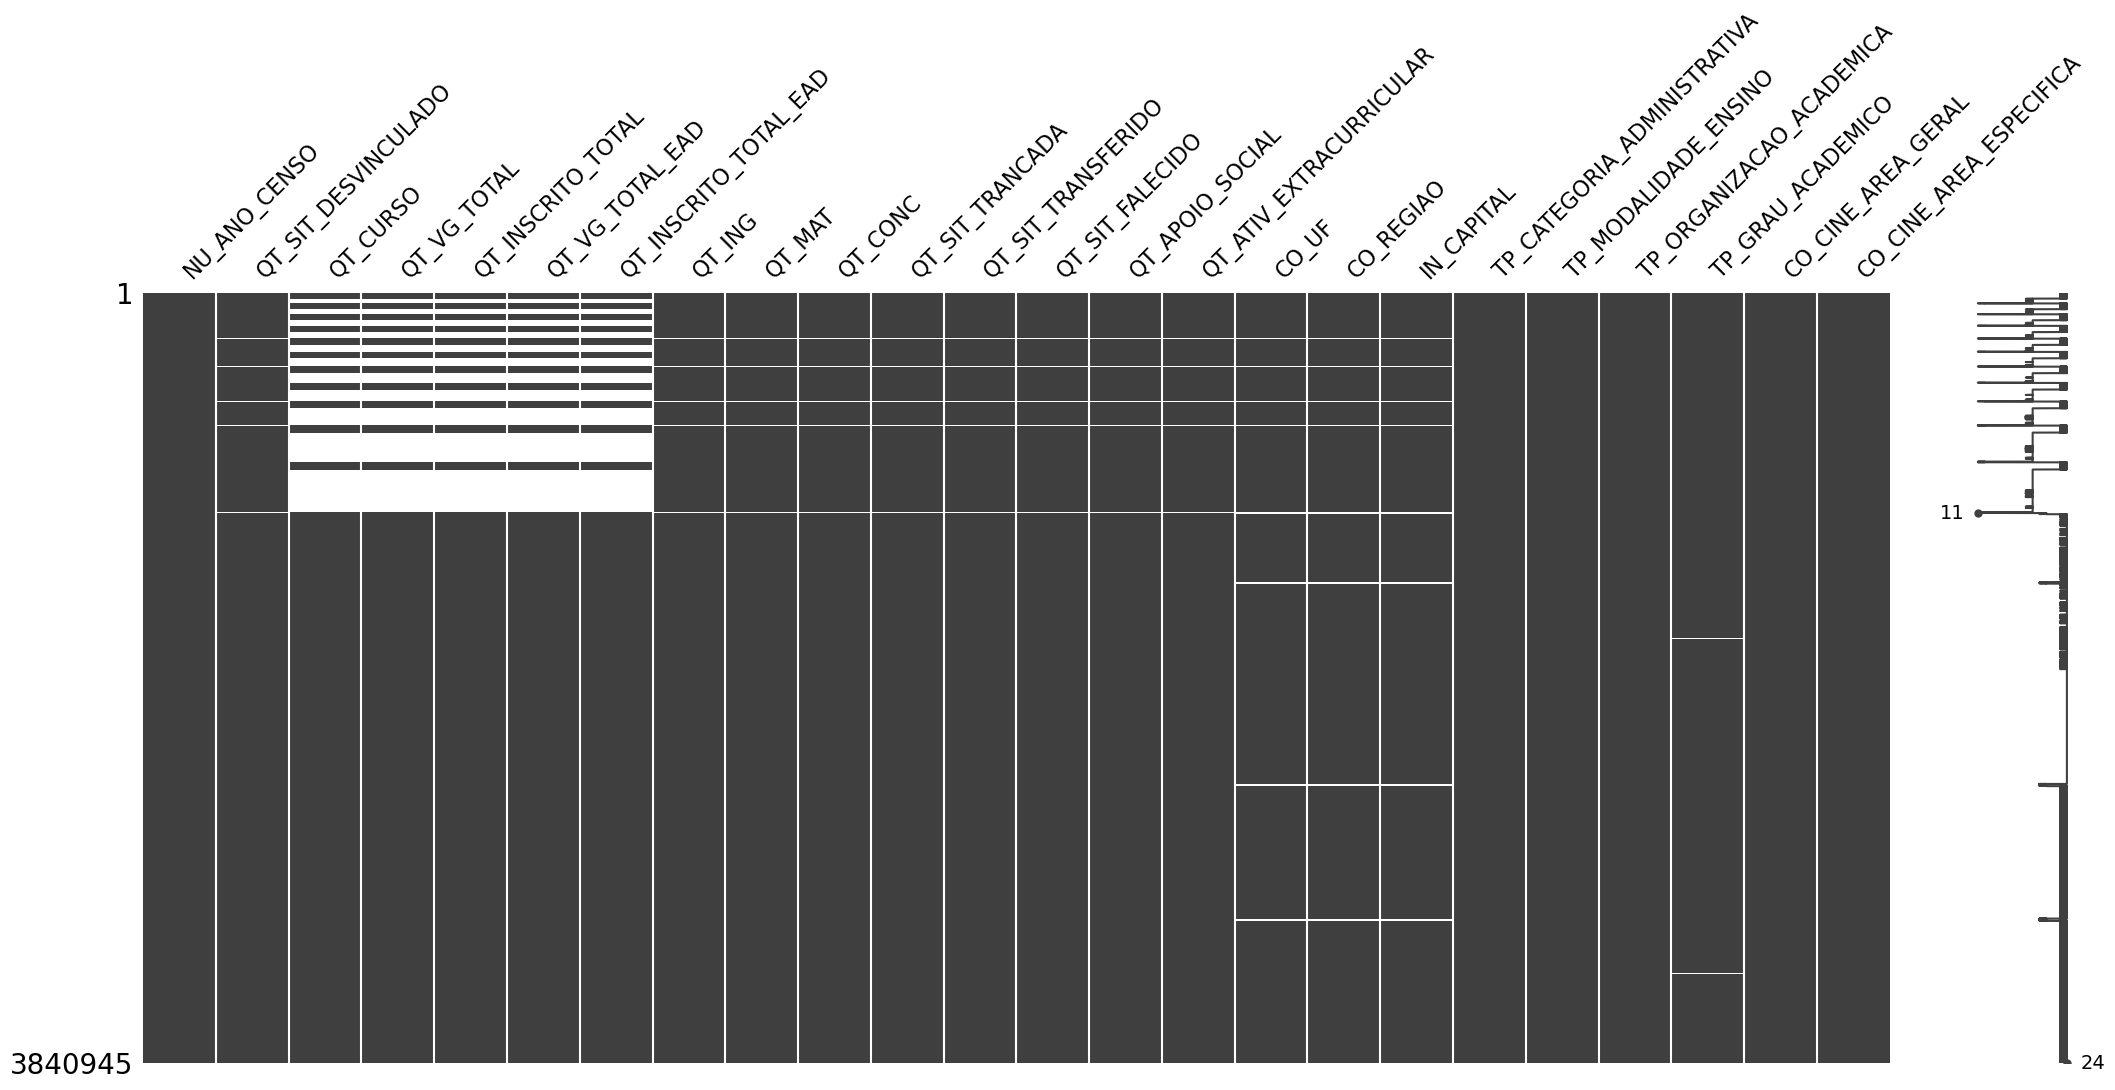

In [28]:
# Matriz de valores ausentes
msno.matrix(df)
plt.show()

In [29]:
tabela_na = pd.DataFrame({
    'Quantidade_NA': df.isna().sum(),
    'Percentual_NA': df.isna().mean() * 100
}).sort_values('Percentual_NA', ascending=False)

tabela_na[tabela_na['Quantidade_NA'] > 0]

,Quantidade_NA,Percentual_NA
QT_CURSO,726856,18.923885
QT_VG_TOTAL,726856,18.923885
QT_INSCRITO_TOTAL,726856,18.923885
QT_VG_TOTAL_EAD,726856,18.923885
QT_INSCRITO_TOTAL_EAD,726856,18.923885
IN_CAPITAL,57073,1.485910
CO_REGIAO,57073,1.485910
CO_UF,57073,1.485910
QT_SIT_FALECIDO,19574,0.509614
QT_SIT_DESVINCULADO,19574,0.509614


In [30]:
variaveis_verificar = [
    'QT_APOIO_SOCIAL',
    'QT_SIT_FALECIDO',
    'QT_ATIV_EXTRACURRICULAR',
    'QT_SIT_DESVINCULADO',
    'QT_SIT_TRANSFERIDO',
    'QT_SIT_TRANCADA',
    'QT_CONC',
    'QT_MAT',
    'QT_ING'
]

df[variaveis_verificar].isna().all(axis=1).sum()

19574

**Tratamento de valores ausentes nas variáveis quantitativas**

Foi identificada a presença de 19.574 valores ausentes, correspondentes a aproximadamente 0,51% das observações, nas variáveis `QT_APOIO_SOCIAL`, `QT_SIT_FALECIDO`, `QT_ATIV_EXTRACURRICULAR`, `QT_SIT_DESVINCULADO`, `QT_SIT_TRANSFERIDO`, `QT_SIT_TRANCADA`, `QT_CONC`, `QT_MAT` e `QT_ING`. A análise dos padrões de ausência indicou que esses valores ausentes estão concentrados nos mesmos registros, caracterizando a ausência simultânea dessas informações.

Considerando que essas variáveis possuem papel relevante na caracterização do fluxo e da situação acadêmica dos estudantes e que a quantidade de registros afetados corresponde a uma pequena parcela da base, optou-se pela exclusão dessas observações em vez da imputação dos valores. Essa decisão evita a introdução de valores artificialmente estimados em um conjunto de variáveis diretamente relacionado à modelagem do desvinculamento.

In [31]:
variaveis_nan = [
    'QT_APOIO_SOCIAL',
    'QT_SIT_FALECIDO',
    'QT_ATIV_EXTRACURRICULAR',
    'QT_SIT_DESVINCULADO',
    'QT_SIT_TRANSFERIDO',
    'QT_SIT_TRANCADA',
    'QT_CONC',
    'QT_MAT',
    'QT_ING'
]

df = df.dropna(subset=variaveis_nan).copy()

In [32]:
tabela_na = pd.DataFrame({
    'Quantidade_NA': df.isna().sum(),
    'Percentual_NA': df.isna().mean() * 100
}).sort_values('Percentual_NA', ascending=False)

tabela_na[tabela_na['Quantidade_NA'] > 0]

,Quantidade_NA,Percentual_NA
QT_CURSO,726856,19.020817
QT_VG_TOTAL,726856,19.020817
QT_INSCRITO_TOTAL,726856,19.020817
QT_VG_TOTAL_EAD,726856,19.020817
QT_INSCRITO_TOTAL_EAD,726856,19.020817
CO_UF,37499,0.981297
IN_CAPITAL,37499,0.981297
CO_REGIAO,37499,0.981297
TP_GRAU_ACADEMICO,8079,0.211416


In [33]:
variaveis_verificar_1 = [
    'CO_UF',
    'IN_CAPITAL',
    'CO_REGIAO'
]

df[variaveis_verificar_1].isna().all(axis=1).sum()

37499

In [34]:
df = df.dropna(subset=variaveis_verificar_1).copy()

In [35]:
tabela_na = pd.DataFrame({
    'Quantidade_NA': df.isna().sum(),
    'Percentual_NA': df.isna().mean() * 100
}).sort_values('Percentual_NA', ascending=False)

tabela_na[tabela_na['Quantidade_NA'] > 0]

,Quantidade_NA,Percentual_NA
QT_CURSO,726464,19.198958
QT_VG_TOTAL,726464,19.198958
QT_INSCRITO_TOTAL,726464,19.198958
QT_VG_TOTAL_EAD,726464,19.198958
QT_INSCRITO_TOTAL_EAD,726464,19.198958
TP_GRAU_ACADEMICO,8014,0.211794


In [36]:
df = df.dropna(subset='TP_GRAU_ACADEMICO').copy()

In [37]:
tabela_na = pd.DataFrame({
    'Quantidade_NA': df.isna().sum(),
    'Percentual_NA': df.isna().mean() * 100
}).sort_values('Percentual_NA', ascending=False)

tabela_na[tabela_na['Quantidade_NA'] > 0]

,Quantidade_NA,Percentual_NA
QT_CURSO,726302,19.235416
QT_VG_TOTAL,726302,19.235416
QT_INSCRITO_TOTAL,726302,19.235416
QT_VG_TOTAL_EAD,726302,19.235416
QT_INSCRITO_TOTAL_EAD,726302,19.235416


In [38]:
variaveis_fluxo = [
    'QT_CURSO',
    'QT_VG_TOTAL',
    'QT_INSCRITO_TOTAL',
    'QT_ING',
    'QT_MAT',
    'QT_CONC',
    'QT_SIT_TRANCADA',
    'QT_SIT_TRANSFERIDO',
    'QT_SIT_FALECIDO',
    'QT_APOIO_SOCIAL',
    'QT_ATIV_EXTRACURRICULAR',
    'QT_SIT_DESVINCULADO'
]

df[variaveis_fluxo].isna().sum()

QT_CURSO                   726302
QT_VG_TOTAL                726302
QT_INSCRITO_TOTAL          726302
QT_ING                          0
QT_MAT                          0
QT_CONC                         0
QT_SIT_TRANCADA                 0
QT_SIT_TRANSFERIDO              0
QT_SIT_FALECIDO                 0
QT_APOIO_SOCIAL                 0
QT_ATIV_EXTRACURRICULAR         0
QT_SIT_DESVINCULADO             0
dtype: int64

In [39]:
df[
    ['QT_CURSO', 'QT_VG_TOTAL', 'QT_INSCRITO_TOTAL']
].isna().all(axis=1).sum()

726302

In [40]:
df.loc[
    df['QT_CURSO'].isna(),
    'TP_MODALIDADE_ENSINO'
].value_counts(dropna=False)

TP_MODALIDADE_ENSINO
2    726302
Name: count, dtype: int64

**conclusão da análise dos valores ausentes**

A análise mostrou que `QT_CURSO`, `QT_VG_TOTAL` e `QT_INSCRITO_TOTAL` apresentam valores ausentes em aproximadamente 19,24% das observações. Verificou-se que esses registros correspondem exclusivamente à modalidade de ensino a distância (`TP_MODALIDADE_ENSINO = 2`). Entretanto, a consulta ao dicionário de dados não indica que essas três variáveis sejam, de forma geral, não aplicáveis ao EAD. Portanto, não é adequado assumir que os valores ausentes representam simplesmente informações que não deveriam existir, nem realizar uma imputação sem antes compreender melhor esse padrão. Além disso, o dicionário apresenta variáveis específicas para EAD, como `QT_VG_TOTAL_EAD` e `QT_INSCRITO_TOTAL_EAD`, que podem ajudar a compreender e tratar essa situação. Dessa forma, optou-se por investigar essas variáveis antes de definir o tratamento dos valores ausentes.

A estratégia a seguir consiste em criar uma variável ajustada que utilize a informação mais adequada para cada modalidade de ensino. Para os cursos presenciais, mantém-se o valor de `QT_INSCRITO_TOTAL`. Já para os cursos EAD (`TP_MODALIDADE_ENSINO = 2`), utiliza-se `QT_INSCRITO_TOTAL_EAD`, que é uma variável específica para essa modalidade.

Dessa forma, evita-se realizar uma imputação arbitrária dos valores ausentes e busca-se aproveitar uma informação específica disponível na própria base de dados.

In [41]:
df['QT_VG_TOTAL_AJUSTADO'] = df['QT_VG_TOTAL']

df.loc[
    df['TP_MODALIDADE_ENSINO'] == 2,
    'QT_VG_TOTAL_AJUSTADO'
] = df.loc[
    df['TP_MODALIDADE_ENSINO'] == 2,
    'QT_VG_TOTAL_EAD'
]

In [42]:
df['QT_INSCRITO_TOTAL_AJUSTADO'] = df['QT_INSCRITO_TOTAL']

df.loc[
    df['TP_MODALIDADE_ENSINO'] == 2,
    'QT_INSCRITO_TOTAL_AJUSTADO'
] = df.loc[
    df['TP_MODALIDADE_ENSINO'] == 2,
    'QT_INSCRITO_TOTAL_EAD'
]

In [43]:
tabela_na = pd.DataFrame({
    'Quantidade_NA': df.isna().sum(),
    'Percentual_NA': df.isna().mean() * 100
}).sort_values('Percentual_NA', ascending=False)

tabela_na[tabela_na['Quantidade_NA'] > 0]

,Quantidade_NA,Percentual_NA
QT_INSCRITO_TOTAL_AJUSTADO,726302,19.235416
QT_CURSO,726302,19.235416
QT_VG_TOTAL,726302,19.235416
QT_INSCRITO_TOTAL,726302,19.235416
QT_VG_TOTAL_EAD,726302,19.235416
QT_INSCRITO_TOTAL_EAD,726302,19.235416
QT_VG_TOTAL_AJUSTADO,726302,19.235416


**Conclusão da análise dos valores ausentes**

A análise mostrou que `QT_INSCRITO_TOTAL`, `QT_VG_TOTAL`, `QT_INSCRITO_TOTAL_EAD` e `QT_VG_TOTAL_EAD` apresentam valores ausentes nas mesmas **726.302 observações (19,24% da base)**. Portanto, a utilização das variáveis específicas de EAD não foi suficiente para preencher os valores ausentes das variáveis gerais.

Além disso, verificou-se que `QT_INSCRITO_TOTAL_AJUSTADO` e `QT_VG_TOTAL_AJUSTADO` também permanecem com os mesmos valores ausentes. Dessa forma, **não é adequado realizar uma imputação neste momento**, pois ainda não está claro o motivo desse padrão de ausência.

Assim, opta-se por **investigar a natureza dessas 726.302 observações antes de definir o tratamento dos valores ausentes**, evitando a introdução de valores que não tenham justificativa nos dados.

**Justificativa da exclusão das variáveis**

As variáveis `QT_CURSO`, `QT_VG_TOTAL` e `QT_INSCRITO_TOTAL`, bem como suas respectivas variáveis específicas para EAD, apresentam valores ausentes em aproximadamente **19,24% das observações**. Como esses valores ausentes ocorrem de forma conjunta, a utilização de métodos de imputação poderia introduzir informações artificiais na base. Dessa forma, optou-se por **não utilizar essas variáveis na etapa de modelagem**, priorizando um conjunto de dados mais consistente e evitando a adoção de procedimentos de imputação complexos e sem justificativa suficiente.

In [45]:
variaveis_problematicas = [
    'QT_CURSO',
    'QT_VG_TOTAL',
    'QT_INSCRITO_TOTAL',
    'QT_VG_TOTAL_EAD',
    'QT_INSCRITO_TOTAL_EAD',
    'QT_VG_TOTAL_AJUSTADO',
    'QT_INSCRITO_TOTAL_AJUSTADO'
]

In [46]:
variaveis_independentes = [
    'NU_ANO_CENSO',
    'QT_SIT_DESVINCULADO',
    'QT_ING',
    'QT_MAT',
    'QT_CONC',
    'QT_SIT_TRANCADA',
    'QT_SIT_TRANSFERIDO',
    'QT_SIT_FALECIDO',
    'QT_APOIO_SOCIAL',
    'QT_ATIV_EXTRACURRICULAR',
    'CO_UF',
    'CO_REGIAO',
    'IN_CAPITAL',
    'TP_CATEGORIA_ADMINISTRATIVA',
    'TP_MODALIDADE_ENSINO',
    'TP_ORGANIZACAO_ACADEMICA',
    'TP_GRAU_ACADEMICO',
    'CO_CINE_AREA_GERAL',
    'CO_CINE_AREA_ESPECIFICA'
]


In [47]:
df = df[variaveis_independentes]

In [48]:
tabela_na = pd.DataFrame({
    'Quantidade_NA': df.isna().sum(),
    'Percentual_NA': df.isna().mean() * 100
}).sort_values('Percentual_NA', ascending=False)

tabela_na

,Quantidade_NA,Percentual_NA
NU_ANO_CENSO,0,0.0
CO_UF,0,0.0
CO_CINE_AREA_GERAL,0,0.0
TP_GRAU_ACADEMICO,0,0.0
TP_ORGANIZACAO_ACADEMICA,0,0.0
TP_MODALIDADE_ENSINO,0,0.0
TP_CATEGORIA_ADMINISTRATIVA,0,0.0
IN_CAPITAL,0,0.0
CO_REGIAO,0,0.0
QT_ATIV_EXTRACURRICULAR,0,0.0


**Verificação dos valores ausentes após o tratamento**

Após a exclusão das variáveis que apresentavam aproximadamente 19,24% de valores ausentes, foi realizada uma nova verificação da base de dados. Observou-se que todas as variáveis selecionadas para a etapa de modelagem apresentam **0 valores ausentes**, garantindo um conjunto de dados completo para as etapas posteriores de transformação, treinamento e avaliação dos modelos.

### 3.3 Tratando outliers

Iniciamos usando o critério IQR para identificar os possíveis outliers.

In [49]:
colunas_sem_ANO = df.columns.to_list()[1:]

In [50]:
colunas_sem_ANO

['QT_SIT_DESVINCULADO',
 'QT_ING',
 'QT_MAT',
 'QT_CONC',
 'QT_SIT_TRANCADA',
 'QT_SIT_TRANSFERIDO',
 'QT_SIT_FALECIDO',
 'QT_APOIO_SOCIAL',
 'QT_ATIV_EXTRACURRICULAR',
 'CO_UF',
 'CO_REGIAO',
 'IN_CAPITAL',
 'TP_CATEGORIA_ADMINISTRATIVA',
 'TP_MODALIDADE_ENSINO',
 'TP_ORGANIZACAO_ACADEMICA',
 'TP_GRAU_ACADEMICO',
 'CO_CINE_AREA_GERAL',
 'CO_CINE_AREA_ESPECIFICA']

In [51]:
variaveis_numericas = [var for var in colunas_sem_ANO if var.startswith('QT') or var.startswith('DELTA')]

In [52]:
variaveis_numericas

['QT_SIT_DESVINCULADO',
 'QT_ING',
 'QT_MAT',
 'QT_CONC',
 'QT_SIT_TRANCADA',
 'QT_SIT_TRANSFERIDO',
 'QT_SIT_FALECIDO',
 'QT_APOIO_SOCIAL',
 'QT_ATIV_EXTRACURRICULAR']

In [55]:
print('Percentual de possíveis outliers\n')

for var in variaveis_numericas:
    Q1 = df[var].quantile(0.25)
    Q3 = df[var].quantile(0.75)
    IQR = Q3 - Q1

    # print('IQR: {}'.format(IQR))
    
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[var] < limite_inferior) |
        (df[var] > limite_superior)
    ]
    
    percentual = len(outliers) / len(df) * 100

    print(f'{var}: ---------------- {percentual:.2f}%')

Percentual de possíveis outliers

QT_SIT_DESVINCULADO: ---------------- 15.42%
QT_ING: ---------------- 16.90%
QT_MAT: ---------------- 16.94%
QT_CONC: ---------------- 17.97%
QT_SIT_TRANCADA: ---------------- 13.89%
QT_SIT_TRANSFERIDO: ---------------- 9.00%
QT_SIT_FALECIDO: ---------------- 0.47%
QT_APOIO_SOCIAL: ---------------- 11.76%
QT_ATIV_EXTRACURRICULAR: ---------------- 18.45%


**Análise de valores extremos**

A identificação de possíveis valores extremos foi realizada pelo método do intervalo interquartil (IQR). Inicialmente, foi utilizado o critério de $1,5 \times IQR$. Entretanto, devido à elevada proporção de observações classificadas como potenciais outliers, adotou-se um critério mais conservador, utilizando o limite de $4,5 \times IQR$.

Mesmo com esse critério, algumas variáveis apresentaram proporções relativamente elevadas de possíveis valores extremos. Considerando que as variáveis analisadas são predominantemente de contagem e que valores elevados podem representar diferenças reais entre cursos e instituições, optou-se por **não excluir essas observações**, uma vez que a classificação pelo IQR não implica que os valores sejam erros de registro.

### 3.4 Investigando o nível de assimetria das variáveis numéricas

In [56]:
assimetria = df[variaveis_numericas].skew()

In [57]:
print(assimetria.sort_values(ascending=False))

QT_SIT_FALECIDO            385.142869
QT_SIT_TRANSFERIDO         114.314550
QT_CONC                     47.706495
QT_ATIV_EXTRACURRICULAR     41.938487
QT_SIT_DESVINCULADO         38.376177
QT_APOIO_SOCIAL             31.125537
QT_SIT_TRANCADA             28.507321
QT_ING                      22.945824
QT_MAT                      16.365898
dtype: float64


A análise da assimetria permite identificar variáveis com distribuições muito concentradas em valores baixos e caudas longas. A transformação `log1p` será aplicada às variáveis porque são de contagem não negativas.

In [60]:
variaveis_log = [
    'QT_SIT_FALECIDO',              
    'QT_SIT_TRANSFERIDO',               
    'QT_CONC',                          
    'QT_ATIV_EXTRACURRICULAR',           
    'QT_SIT_DESVINCULADO',              
    'QT_APOIO_SOCIAL',                   
    'QT_SIT_TRANCADA',                   
    'QT_ING',                            
    'QT_MAT'
]

In [61]:
for var in variaveis_log:
    df[f'{var}_LOG'] = np.log1p(df[var])

In [62]:
assimetria_log = df[
    [f'{var}_LOG' for var in variaveis_log]
].skew()

print(assimetria_log.sort_values(ascending=False))

QT_SIT_FALECIDO_LOG            19.421253
QT_SIT_TRANSFERIDO_LOG          5.108773
QT_APOIO_SOCIAL_LOG             3.768256
QT_ATIV_EXTRACURRICULAR_LOG     3.103077
QT_CONC_LOG                     2.020449
QT_SIT_TRANCADA_LOG             1.882484
QT_SIT_DESVINCULADO_LOG         1.256398
QT_MAT_LOG                      1.077497
QT_ING_LOG                      1.069098
dtype: float64


**Conclusão**

As transformações logarítmicas reduziram a assimetria de várias variáveis de contagem. A redução da assimetria é um resultado descritivo e não garante, por si só, melhor desempenho preditivo; essa contribuição deverá ser avaliada na modelagem.

Após as transformações que reduziram as assimetrias das variáveis, devemos verificar se não há novos valores ausentes.

In [64]:
# Verificação de valores ausentes após a engenharia de atributos.
tabela_na_final = pd.DataFrame({
    'Quantidade_NA': df.isna().sum(),
    'Percentual_NA': df.isna().mean() * 100
}).sort_values('Percentual_NA', ascending=False)

display(tabela_na_final)


,Quantidade_NA,Percentual_NA
NU_ANO_CENSO,0,0.0
QT_SIT_DESVINCULADO,0,0.0
QT_ING_LOG,0,0.0
QT_SIT_TRANCADA_LOG,0,0.0
QT_APOIO_SOCIAL_LOG,0,0.0
QT_SIT_DESVINCULADO_LOG,0,0.0
QT_ATIV_EXTRACURRICULAR_LOG,0,0.0
QT_CONC_LOG,0,0.0
QT_SIT_TRANSFERIDO_LOG,0,0.0
QT_SIT_FALECIDO_LOG,0,0.0


### 3.5 Análise de correlação

In [68]:
df.columns.to_list()

['NU_ANO_CENSO',
 'QT_SIT_DESVINCULADO',
 'QT_ING',
 'QT_MAT',
 'QT_CONC',
 'QT_SIT_TRANCADA',
 'QT_SIT_TRANSFERIDO',
 'QT_SIT_FALECIDO',
 'QT_APOIO_SOCIAL',
 'QT_ATIV_EXTRACURRICULAR',
 'CO_UF',
 'CO_REGIAO',
 'IN_CAPITAL',
 'TP_CATEGORIA_ADMINISTRATIVA',
 'TP_MODALIDADE_ENSINO',
 'TP_ORGANIZACAO_ACADEMICA',
 'TP_GRAU_ACADEMICO',
 'CO_CINE_AREA_GERAL',
 'CO_CINE_AREA_ESPECIFICA',
 'QT_SIT_FALECIDO_LOG',
 'QT_SIT_TRANSFERIDO_LOG',
 'QT_CONC_LOG',
 'QT_ATIV_EXTRACURRICULAR_LOG',
 'QT_SIT_DESVINCULADO_LOG',
 'QT_APOIO_SOCIAL_LOG',
 'QT_SIT_TRANCADA_LOG',
 'QT_ING_LOG',
 'QT_MAT_LOG']

In [71]:
lista_QT = [var for var in df.columns.to_list() if var.startswith('QT')]

In [74]:
corr_QT = df[lista_QT].corr()

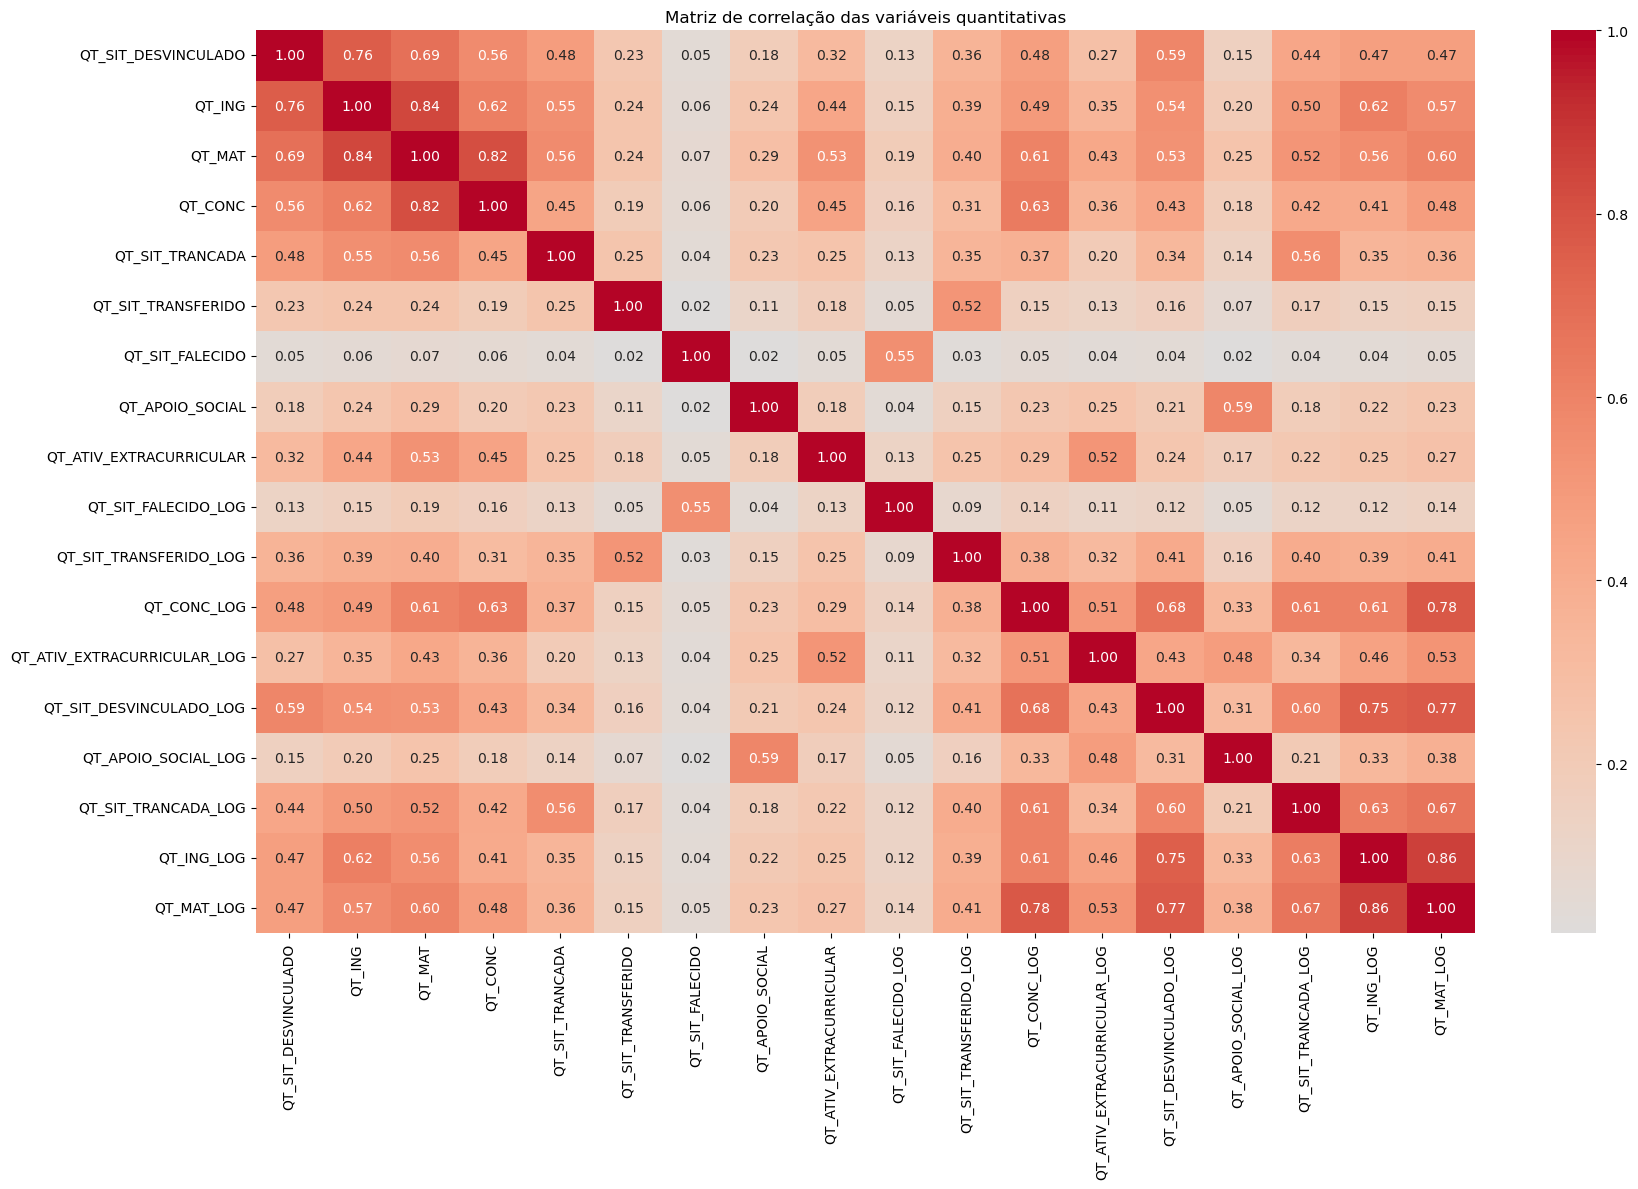

In [75]:
plt.figure(figsize=(18, 12))
sns.heatmap(corr_QT, annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Matriz de correlação das variáveis quantitativas')
plt.tight_layout()
plt.show()

**Análise da matriz de correlação**

A matriz de correlação evidencia associações lineares positivas de diferentes intensidades entre as variáveis analisadas. Em relação à variável-alvo `QT_SIT_DESVINCULADO`, destacam-se as correlações com `QT_ING` (0,76), `QT_MAT` (0,69), `QT_CONC` (0,56) e `QT_SIT_TRANCADA` (0,48). Esses resultados indicam que o número de estudantes desvinculados apresenta associação com o volume de ingressantes, matriculados, concluintes e estudantes com matrícula trancada. Em contrapartida, `QT_SIT_FALECIDO` apresenta correlação fraca com o alvo (0,05), enquanto `QT_SIT_TRANSFERIDO` (0,23) e `QT_APOIO_SOCIAL` (0,18) também apresentam associações relativamente baixas.

Entre as variáveis preditoras, observam-se correlações elevadas, especialmente entre `QT_ING` e `QT_MAT` (0,84), `QT_MAT` e `QT_CONC` (0,82), `QT_ING_LOG` e `QT_MAT_LOG` (0,86), além de `QT_CONC_LOG` e `QT_MAT_LOG` (0,78). Essas associações sugerem possível redundância de informação entre variáveis relacionadas ao tamanho e ao fluxo acadêmico dos cursos. Também se observa que algumas variáveis originais e suas versões transformadas apresentam correlações moderadas ou elevadas, o que é esperado, uma vez que as transformações preservam parte da informação original.

Diante desses resultados, a matriz sugere que algumas variáveis possuem potencial para contribuir com a previsão da variável-alvo, mas também revela possível multicolinearidade entre os preditores. A correlação, entretanto, não implica causalidade e, isoladamente, não determina quais variáveis devem ser mantidas no modelo. Recomenda-se evitar a inclusão simultânea de variáveis originais e transformadas sem uma justificativa clara, pois isso pode aumentar a redundância. A seleção definitiva deverá considerar o objetivo da análise e o desempenho dos modelos de Machine Learning.

### 3.6 Multicolinearidade

In [78]:
lista_variaveis_preditoras = [var for var in df.columns.to_list() if var.startswith('QT') and 'DESVINCULADO' not in var]

In [79]:
lista_variaveis_preditoras

['QT_ING',
 'QT_MAT',
 'QT_CONC',
 'QT_SIT_TRANCADA',
 'QT_SIT_TRANSFERIDO',
 'QT_SIT_FALECIDO',
 'QT_APOIO_SOCIAL',
 'QT_ATIV_EXTRACURRICULAR',
 'QT_SIT_FALECIDO_LOG',
 'QT_SIT_TRANSFERIDO_LOG',
 'QT_CONC_LOG',
 'QT_ATIV_EXTRACURRICULAR_LOG',
 'QT_APOIO_SOCIAL_LOG',
 'QT_SIT_TRANCADA_LOG',
 'QT_ING_LOG',
 'QT_MAT_LOG']

In [80]:
corr_preditoras = df[lista_variaveis_preditoras].corr()

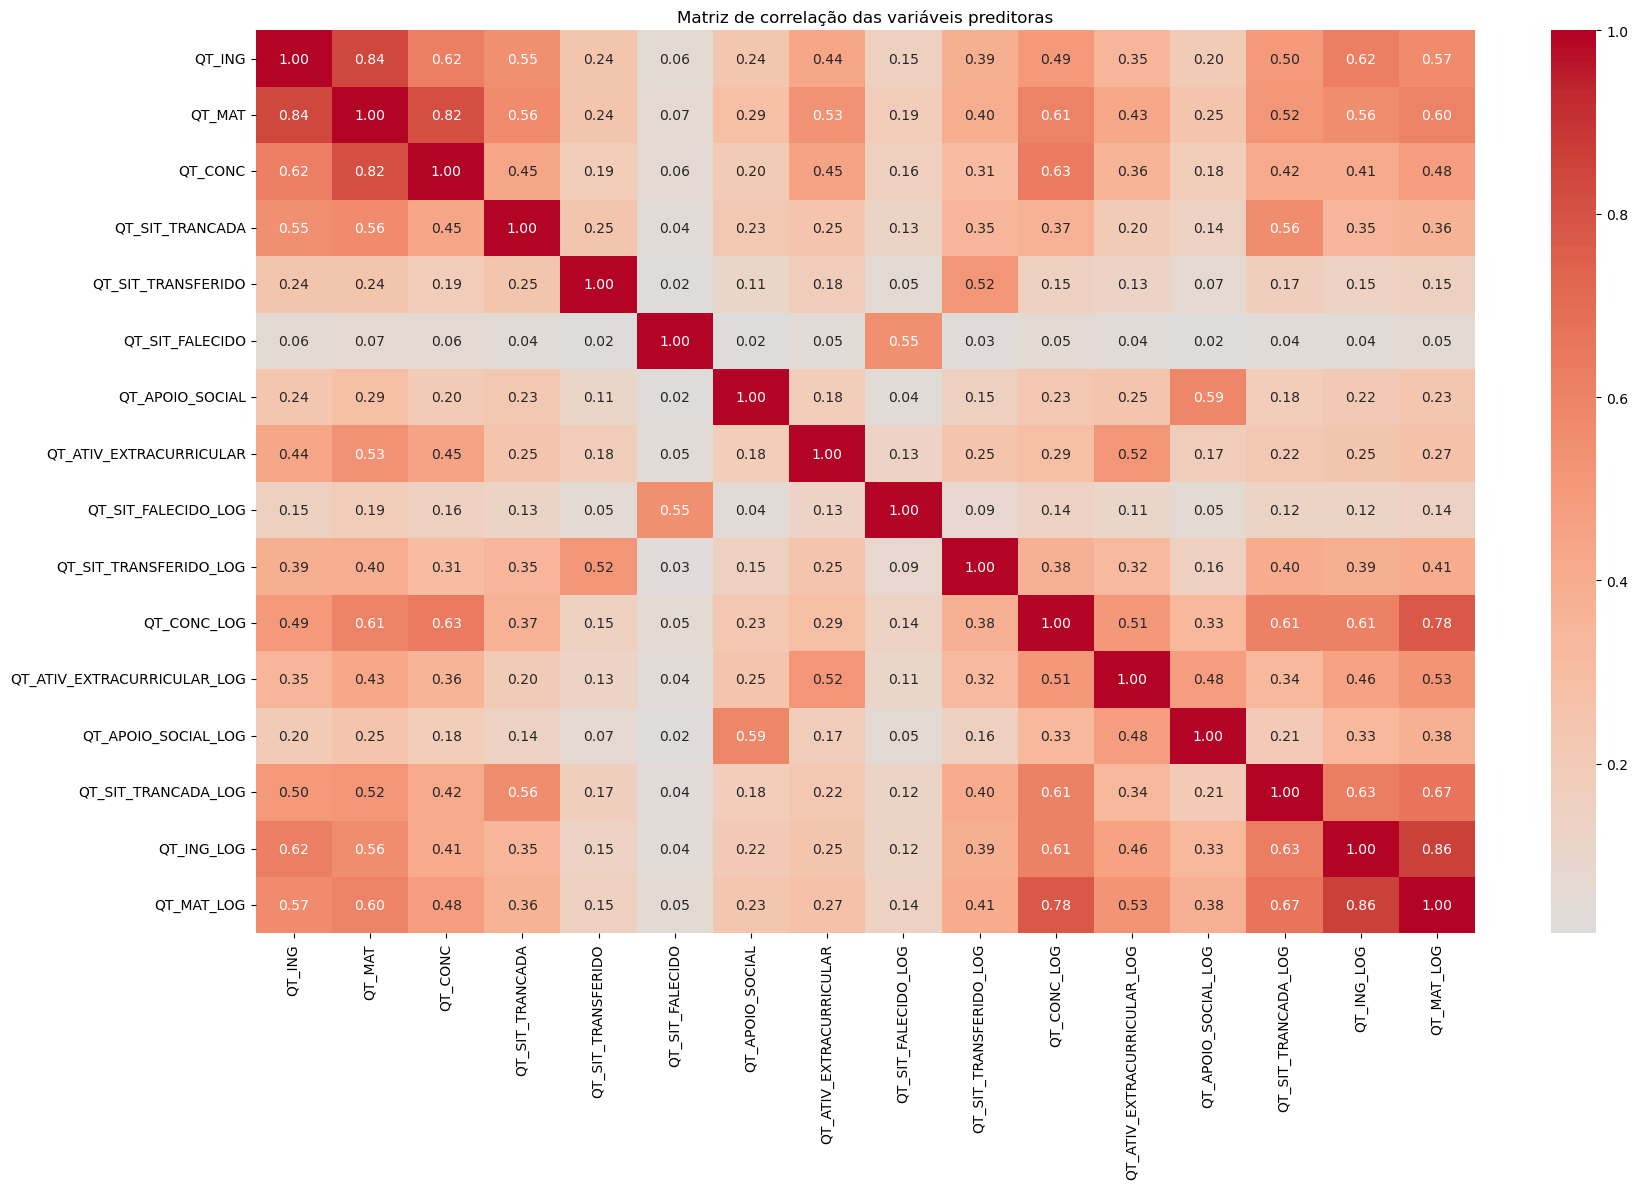

In [81]:
plt.figure(figsize=(18, 12))
sns.heatmap(corr_preditoras, annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Matriz de correlação das variáveis preditoras')
plt.tight_layout()
plt.show()

**Análise da matriz de correlação entre as variáveis preditoras**

A matriz de correlação evidencia associações lineares positivas de diferentes intensidades entre as variáveis preditoras. Destacam-se as correlações elevadas entre `QT_ING` e `QT_MAT` (0,84), `QT_MAT` e `QT_CONC` (0,82), `QT_CONC_LOG` e `QT_MAT_LOG` (0,78) e `QT_ING_LOG` e `QT_MAT_LOG` (0,86). Essas associações sugerem possível redundância de informações entre variáveis relacionadas ao tamanho e ao fluxo acadêmico dos cursos. Também se observa correlação moderada entre `QT_SIT_TRANCADA` e `QT_SIT_TRANCADA_LOG` (0,56), bem como entre `QT_APOIO_SOCIAL` e `QT_APOIO_SOCIAL_LOG` (0,59).

Por outro lado, algumas variáveis apresentam correlações fracas com as demais, como `QT_SIT_FALECIDO`, cujas correlações com a maioria dos preditores são próximas de zero. Além disso, a presença simultânea de variáveis originais e suas versões transformadas pode introduzir redundância no conjunto de dados, uma vez que ambas carregam informações relacionadas.

Diante desses resultados, recomenda-se avaliar a necessidade de manter simultaneamente as variáveis originais e transformadas, evitando incluir ambas sem uma justificativa clara. Entretanto, correlações elevadas não exigem necessariamente a exclusão de variáveis, pois a decisão depende do algoritmo utilizado e do objetivo da modelagem. A seleção final deverá considerar o desempenho preditivo dos modelos e a contribuição de cada variável, lembrando que correlação não implica causalidade.

### 3.7 Preparação das variáveis categóricas

As variáveis categóricas serão mantidas como categorias nesta etapa. O `OneHotEncoder` não deve ser ajustado em toda a base antes da divisão treino/teste, pois o pré-processamento deve ser aprendido somente com os dados de treino. Na Parte 4, a codificação será realizada dentro de um `ColumnTransformer`/`Pipeline`, junto com o escalonamento e o modelo, garantindo o tratamento correto durante a validação cruzada.

Identificamos as variáveis categóricas e quantitativas que serão encaminhadas ao pipeline de modelagem.

In [82]:
lista = df.columns.to_list()

In [83]:
lista

['NU_ANO_CENSO',
 'QT_SIT_DESVINCULADO',
 'QT_ING',
 'QT_MAT',
 'QT_CONC',
 'QT_SIT_TRANCADA',
 'QT_SIT_TRANSFERIDO',
 'QT_SIT_FALECIDO',
 'QT_APOIO_SOCIAL',
 'QT_ATIV_EXTRACURRICULAR',
 'CO_UF',
 'CO_REGIAO',
 'IN_CAPITAL',
 'TP_CATEGORIA_ADMINISTRATIVA',
 'TP_MODALIDADE_ENSINO',
 'TP_ORGANIZACAO_ACADEMICA',
 'TP_GRAU_ACADEMICO',
 'CO_CINE_AREA_GERAL',
 'CO_CINE_AREA_ESPECIFICA',
 'QT_SIT_FALECIDO_LOG',
 'QT_SIT_TRANSFERIDO_LOG',
 'QT_CONC_LOG',
 'QT_ATIV_EXTRACURRICULAR_LOG',
 'QT_SIT_DESVINCULADO_LOG',
 'QT_APOIO_SOCIAL_LOG',
 'QT_SIT_TRANCADA_LOG',
 'QT_ING_LOG',
 'QT_MAT_LOG']

In [84]:
var_cat = [
    var for var in df.columns
    if var.startswith(('CO_', 'TP_', 'IN_'))
]

In [91]:
var_num = [var for var in lista if var.startswith('QT')]

In [92]:
var_num

['QT_SIT_DESVINCULADO',
 'QT_ING',
 'QT_MAT',
 'QT_CONC',
 'QT_SIT_TRANCADA',
 'QT_SIT_TRANSFERIDO',
 'QT_SIT_FALECIDO',
 'QT_APOIO_SOCIAL',
 'QT_ATIV_EXTRACURRICULAR',
 'QT_SIT_FALECIDO_LOG',
 'QT_SIT_TRANSFERIDO_LOG',
 'QT_CONC_LOG',
 'QT_ATIV_EXTRACURRICULAR_LOG',
 'QT_SIT_DESVINCULADO_LOG',
 'QT_APOIO_SOCIAL_LOG',
 'QT_SIT_TRANCADA_LOG',
 'QT_ING_LOG',
 'QT_MAT_LOG']

In [85]:
var_cat

['CO_UF',
 'CO_REGIAO',
 'IN_CAPITAL',
 'TP_CATEGORIA_ADMINISTRATIVA',
 'TP_MODALIDADE_ENSINO',
 'TP_ORGANIZACAO_ACADEMICA',
 'TP_GRAU_ACADEMICO',
 'CO_CINE_AREA_GERAL',
 'CO_CINE_AREA_ESPECIFICA']

As variáveis categóricas serão codificadas na etapa de modelagem, após a divisão entre treino e teste. Isso evita que categorias observadas apenas no teste participem do ajuste do encoder.

In [86]:
# Apenas identificamos as variáveis categóricas nesta etapa.
# O OneHotEncoder será ajustado dentro do Pipeline na Parte 4.
var_cat

['CO_UF',
 'CO_REGIAO',
 'IN_CAPITAL',
 'TP_CATEGORIA_ADMINISTRATIVA',
 'TP_MODALIDADE_ENSINO',
 'TP_ORGANIZACAO_ACADEMICA',
 'TP_GRAU_ACADEMICO',
 'CO_CINE_AREA_GERAL',
 'CO_CINE_AREA_ESPECIFICA']

In [87]:
# Não ajustar o encoder na base completa.
# A codificação será feita posteriormente com ColumnTransformer + Pipeline.
df[var_cat].head()


,CO_UF,CO_REGIAO,IN_CAPITAL,TP_CATEGORIA_ADMINISTRATIVA,TP_MODALIDADE_ENSINO,TP_ORGANIZACAO_ACADEMICA,TP_GRAU_ACADEMICO,CO_CINE_AREA_GERAL,CO_CINE_AREA_ESPECIFICA
0,11.0,1.0,0.0,1,1,1,1.0,7,72
1,11.0,1.0,0.0,1,1,1,2.0,1,11
2,11.0,1.0,0.0,6,1,3,1.0,4,41
3,11.0,1.0,0.0,6,1,3,1.0,4,41
4,11.0,1.0,0.0,6,1,3,2.0,1,11


In [88]:
# Mantemos as categorias originais para que o encoder seja ajustado apenas no treino.
df_X_cat = df[var_cat].copy()


O dataframe `df_X_cat` contém as variáveis categóricas originais, ainda não codificadas.

Verificamos os nomes que as colunas receberam.

In [89]:
df_X_cat.columns.to_list()

['CO_UF',
 'CO_REGIAO',
 'IN_CAPITAL',
 'TP_CATEGORIA_ADMINISTRATIVA',
 'TP_MODALIDADE_ENSINO',
 'TP_ORGANIZACAO_ACADEMICA',
 'TP_GRAU_ACADEMICO',
 'CO_CINE_AREA_GERAL',
 'CO_CINE_AREA_ESPECIFICA']

In [93]:
# Dataframe de preparação: preditores numéricos permitidos + categóricas originais + alvo.
# O alvo fica no dataframe para facilitar a separação de y na Parte 4.
df_final_2 = pd.concat(
    [
        df[['NU_ANO_CENSO']],
        df[var_num],
        df_X_cat,
        df[['QT_SIT_DESVINCULADO']]
    ],
    axis=1
)

# Remover duplicações de colunas preservando a primeira ocorrência.
df_final_2 = df_final_2.loc[:, ~df_final_2.columns.duplicated()].copy()

In [94]:
df_final_2.columns.to_list()

['NU_ANO_CENSO',
 'QT_SIT_DESVINCULADO',
 'QT_ING',
 'QT_MAT',
 'QT_CONC',
 'QT_SIT_TRANCADA',
 'QT_SIT_TRANSFERIDO',
 'QT_SIT_FALECIDO',
 'QT_APOIO_SOCIAL',
 'QT_ATIV_EXTRACURRICULAR',
 'QT_SIT_FALECIDO_LOG',
 'QT_SIT_TRANSFERIDO_LOG',
 'QT_CONC_LOG',
 'QT_ATIV_EXTRACURRICULAR_LOG',
 'QT_SIT_DESVINCULADO_LOG',
 'QT_APOIO_SOCIAL_LOG',
 'QT_SIT_TRANCADA_LOG',
 'QT_ING_LOG',
 'QT_MAT_LOG',
 'CO_UF',
 'CO_REGIAO',
 'IN_CAPITAL',
 'TP_CATEGORIA_ADMINISTRATIVA',
 'TP_MODALIDADE_ENSINO',
 'TP_ORGANIZACAO_ACADEMICA',
 'TP_GRAU_ACADEMICO',
 'CO_CINE_AREA_GERAL',
 'CO_CINE_AREA_ESPECIFICA']

O dataframe `df_final_2` contém o ano do Censo, as variáveis numéricas selecionadas, as variáveis categóricas ainda não codificadas e a variável-alvo `QT_SIT_DESVINCULADO`. Na Parte 4, o alvo deverá ser separado de `X`, e as variáveis categóricas deverão ser codificadas dentro de um pipeline ajustado apenas nos dados de treino.

Verificamos, pela última vez, se ainda há valores ausentes.

In [95]:
df_final_2.isna().sum()

NU_ANO_CENSO                   0
QT_SIT_DESVINCULADO            0
QT_ING                         0
QT_MAT                         0
QT_CONC                        0
QT_SIT_TRANCADA                0
QT_SIT_TRANSFERIDO             0
QT_SIT_FALECIDO                0
QT_APOIO_SOCIAL                0
QT_ATIV_EXTRACURRICULAR        0
QT_SIT_FALECIDO_LOG            0
QT_SIT_TRANSFERIDO_LOG         0
QT_CONC_LOG                    0
QT_ATIV_EXTRACURRICULAR_LOG    0
QT_SIT_DESVINCULADO_LOG        0
QT_APOIO_SOCIAL_LOG            0
QT_SIT_TRANCADA_LOG            0
QT_ING_LOG                     0
QT_MAT_LOG                     0
CO_UF                          0
CO_REGIAO                      0
IN_CAPITAL                     0
TP_CATEGORIA_ADMINISTRATIVA    0
TP_MODALIDADE_ENSINO           0
TP_ORGANIZACAO_ACADEMICA       0
TP_GRAU_ACADEMICO              0
CO_CINE_AREA_GERAL             0
CO_CINE_AREA_ESPECIFICA        0
dtype: int64

## 4. Salvando o dataframe preparado

O caminho abaixo é específico do ambiente local em que o notebook foi desenvolvido. Altere-o se necessário. O arquivo salvo contém variáveis categóricas não codificadas; a codificação deverá ocorrer na etapa de modelagem para evitar vazamento entre treino e teste.

In [96]:
# Ajuste o caminho para a pasta de saída do seu ambiente.
df_final_2.to_csv(
    'dados_preparados.csv',
    index=False
)


In [97]:
%reload_ext watermark
%watermark -a "Mauricio Vinhote"

Author: Mauricio Vinhote



In [98]:
%watermark -v -m

Python implementation: CPython
Python version       : 3.12.7
IPython version      : 8.27.0

Compiler    : MSC v.1929 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 154 Stepping 3, GenuineIntel
CPU cores   : 12
Architecture: 64bit



In [99]:
%watermark --iversions

matplotlib : 3.9.2
missingno  : 0.5.2
numpy      : 1.26.4
pandas     : 2.2.2
seaborn    : 0.13.2
sklearn    : 1.5.1
statsmodels: 0.14.2

